# Single-Image Super-Resolution — SRCNN, ESPCN, SRResNet, SRGAN, EDSR

Five super-resolution networks implemented in PyTorch, trained under one protocol, and compared on a held-out benchmark and on your own smartphone photographs.

| # | Model | Year | Upsampling strategy | Loss | Task |
|---|---|---|---|---|---|
| 1 | **SRCNN** | 2014 | Pre-upsample (bicubic), then 3 convs | pixel | 1 |
| 2 | **ESPCN** | 2016 | Post-upsample, sub-pixel conv | pixel | 2 |
| 3 | **SRResNet** | 2017 | Post-upsample, 16 residual blocks + BN | pixel | 3 |
| 4 | **SRGAN** | 2017 | SRResNet generator + discriminator | pixel + VGG perceptual + adversarial | 4 |
| 5 | **EDSR** | 2017 | Post-upsample, 16 residual blocks, **no** BN | pixel | 5 |

**Bicubic interpolation is included throughout as a baseline.** A super-resolution model that cannot beat bicubic has not learned anything useful, so every table and figure below reports it alongside the five networks.

### Assignment map

| Requirement | Where |
|---|---|
| Architecture diagrams | §5–§9, saved to `figures/architecture_*.png` |
| Training + validation loss curves | §12, `figures/loss_curves_*.png` |
| Test results | §13, `figures/testset_*.png` |
| Model summary / parameter count | §5–§9 (per model) and §15 (combined) |
| Smartphone image comparison | §14, `figures/smartphone_*.png` |
| PSNR, SSIM, inference time, parameters | §13–§15, `results/*.csv` |
| Analysis and discussion | §16 |

Everything is written to `sr_outputs/` — `figures/` for report-ready PNGs, `results/` for CSV/JSON tables, `models/` for checkpoints.

### One thing to read before the numbers

Models 1–3 and 5 share the same data, patches, optimizer and **pixel loss**, but each is trained at its own swept learning rate and schedule (§2, §11), so every architecture is judged at its own best. The trade is that a gap in the results table now reflects architecture *and* tuning together rather than architecture alone.

**SRGAN is deliberately not in that group.** It optimizes a different objective — perceptual and adversarial terms on top of the content loss — and it will almost certainly score *worse* on PSNR and SSIM than the SRResNet it is initialized from. That is not a bug and not a failed run. PSNR rewards conservative, blurry averages; GAN training deliberately trades that away for texture that looks right to a human eye. §16 covers why the metrics and your eyes disagree here, and it is the single most important discussion point in this assignment.

## 1. Setup

In [1]:
# !pip install torch torchvision scikit-image matplotlib numpy pillow

import os, time, json, math, csv, random, zipfile, urllib.request, shutil
from pathlib import Path
from dataclasses import dataclass
from typing import List, Dict, Tuple

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models as tvmodels
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

# ------------------------------------------------------------------ switches
QUICK_MODE = False   # tiny run to check the notebook end to end (minutes, not hours)
PRETRAINED = True    # VGG19 weights for the SRGAN perceptual loss (~550 MB download)

# ------------------------------------------------------------------ output tree
OUT      = Path("sr_outputs")
FIGDIR   = OUT / "figures"
RESDIR   = OUT / "results"
MODELDIR = OUT / "models"
for d in (FIGDIR, RESDIR, MODELDIR):
    d.mkdir(parents=True, exist_ok=True)

def savefig(fig, name, dpi=150):
    """Every figure in the report comes from here."""
    path = FIGDIR / f"{name}.png"
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    print(f"  saved -> {path}")
    return path

print("PyTorch   :", torch.__version__)
print("Device    :", device)
print("Quick mode:", QUICK_MODE)
print("Figures   ->", FIGDIR.resolve())

PyTorch   : 2.7.1+cu128
Device    : cuda
Quick mode: False
Figures   -> D:\Study\MSc\2nd semester\Computer Vision\Assignments\02\sr_outputs\figures


## 2. Configuration

`SCALE = 4` throughout. It is the setting SRGAN/EDSR were designed around and the one where the models actually separate — at ×2 everything looks fine and the comparison is uninformative.

Training is **patch-based**, the standard protocol for super-resolution: random 96×96 crops from the HR images, each downsampled to 24×24 to form the input. Patches rather than whole images because SR is a local problem, a fully convolutional network does not care about input size, and it lets us fill a batch from a handful of 2K photographs.

In [2]:
@dataclass
class Config:
    scale: int = 4
    hr_patch: int = 96          # -> 24x24 LR input at scale 4
    batch_size: int = 16
    epochs: int = 60            # base budget; per-model override in MODEL_HP
    patches_per_image: int = 10 # random crops drawn per source image, per epoch
    lr: float = 1e-3            # base learning rate; per-model override in MODEL_HP
    betas: Tuple[float, float] = (0.9, 0.999)

    # --- SRGAN only ---
    gan_epochs: int = 25
    gan_lr: float = 1e-4
    adv_weight: float = 1e-3    # weight on the adversarial term
    vgg_weight: float = 6e-3    # weight on the VGG perceptual term

    # --- evaluation ---
    max_hr_side: int = 1024     # smartphone photos are downscaled to this before use
    val_fraction: float = 0.10
    test_fraction: float = 0.10

    @property
    def lr_patch(self):
        return self.hr_patch // self.scale


CFG = Config()

# --------------------------------------------------- per-model hyperparameters
# Each network is trained at its own setting rather than under one shared
# recipe. The learning rates were picked by the sweep documented in §11, not by
# taste. `warmup` is the fraction of total steps spent ramping the learning rate
# up from zero before the cosine decay starts, which keeps a 16-block residual
# trunk stable at a high peak rate.
MODEL_HP: Dict[str, dict] = {
    "SRCNN":    dict(lr=0.001,    epochs=CFG.epochs, warmup=0.00),
    "ESPCN":    dict(lr=0.002,    epochs=CFG.epochs, warmup=0.00),
    "SRResNet": dict(lr=0.001, epochs=CFG.epochs, warmup=0.03),
    "EDSR":     dict(lr=0.001,     epochs=CFG.epochs, warmup=0.03),
    "SRGAN":    dict(lr=CFG.gan_lr, epochs=CFG.gan_epochs, warmup=0.00),
}

if QUICK_MODE:
    CFG.epochs, CFG.gan_epochs = 2, 1
    CFG.patches_per_image = 4
    CFG.max_hr_side = 256
    for _hp in MODEL_HP.values():
        _hp["epochs"] = 2
    MODEL_HP["SRGAN"]["epochs"] = 1

assert CFG.hr_patch % CFG.scale == 0, "hr_patch must be divisible by scale"
print(f"scale x{CFG.scale} | HR patch {CFG.hr_patch} -> LR patch {CFG.lr_patch} | "
      f"batch {CFG.batch_size} | {CFG.patches_per_image} patches per image")
print(f"\n{'model':<10}{'lr':>10}{'epochs':>9}{'warmup':>9}")
for _name, _hp in MODEL_HP.items():
    print(f"{_name:<10}{_hp['lr']:>10g}{_hp['epochs']:>9}{_hp['warmup']:>9.0%}")


scale x4 | HR patch 96 -> LR patch 24 | batch 16 | 10 patches per image

model             lr   epochs   warmup
SRCNN          0.001       60       0%
ESPCN          0.002       60       0%
SRResNet       0.001       60       3%
EDSR           0.001       60       3%
SRGAN         0.0001       25       0%


## 3. Dataset

**DIV2K** is the default — 800 (train) + 100 (validation) 2K-resolution photographs, and the standard benchmark for every model in this assignment.

Three ways to supply data, tried in order:

1. `DATA_SOURCE = "div2k_train"` — the full 800-image set, ~3.3 GB. **This is the default here**, and the set every model in this assignment was published on.
2. `DATA_SOURCE = "div2k_valid"` — 100 images, ~430 MB. Much faster to fetch and enough to get the notebook running end to end, at some cost in final quality.
3. `DATA_SOURCE = "folder"` — point `LOCAL_IMAGE_DIR` at any directory of your own images and nothing is downloaded.

The images are split into train / validation / test by file, seeded, so no test image ever contributes a training patch. Every model sees the identical split: **640 train / 80 validation / 80 test**.

Note the memory cost of the full set. The patch dataset decodes each source image once and keeps it, which is what makes patch extraction cheap — but 640 2K photographs held as RGB arrays is roughly **5 GB of RAM**, and the first epoch pays a one-off ~3 minutes decoding them. Drop to `div2k_valid` if that is too much for your machine.

In [3]:
DATA_SOURCE     = "div2k_train"          # "div2k_valid" | "div2k_train" | "folder"
LOCAL_IMAGE_DIR = Path("my_images")      # only used when DATA_SOURCE == "folder"
DATA_ROOT       = Path("sr_data")
DATA_ROOT.mkdir(exist_ok=True)

DIV2K_URLS = {
    "div2k_valid": ("https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_valid_HR.zip", "DIV2K_valid_HR"),
    "div2k_train": ("https://data.vision.ee.ethz.ch/cvl/DIV2K/DIV2K_train_HR.zip", "DIV2K_train_HR"),
}
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}


def _download(url, dest):
    print(f"downloading {url}\n  -> {dest}  (this can take several minutes)")
    def hook(blocks, bs, total):
        if total > 0 and blocks % 200 == 0:
            print(f"\r  {min(blocks*bs/total,1)*100:5.1f}%", end="")
    urllib.request.urlretrieve(url, dest, reporthook=hook)
    print("\r  100.0%")


def prepare_images() -> List[Path]:
    if DATA_SOURCE == "folder":
        files = sorted(p for p in LOCAL_IMAGE_DIR.rglob("*") if p.suffix.lower() in IMG_EXT)
        if not files:
            raise FileNotFoundError(
                f"No images found in {LOCAL_IMAGE_DIR.resolve()}. Put some there, or set "
                f"DATA_SOURCE to 'div2k_valid'.")
        return files

    url, folder = DIV2K_URLS[DATA_SOURCE]
    target, archive = DATA_ROOT / folder, DATA_ROOT / f"{folder}.zip"
    if not target.exists():
        if not archive.exists():
            _download(url, archive)
        print("extracting...")
        with zipfile.ZipFile(archive) as z:
            z.extractall(DATA_ROOT)
    files = sorted(p for p in target.rglob("*") if p.suffix.lower() in IMG_EXT)
    if not files:
        raise RuntimeError(f"{target} contains no images — delete it and re-run.")
    return files


ALL_IMAGES = prepare_images()

rng = random.Random(SEED)
_shuffled = ALL_IMAGES[:]
rng.shuffle(_shuffled)

n_total = len(_shuffled)
if n_total < 4:
    raise ValueError(f"Only {n_total} images available; at least 4 are needed to form a "
                     f"train/val/test split. Add more images or use DATA_SOURCE='div2k_valid'.")

# never let the held-out sets swallow the training set: each is capped at a
# quarter of the images, which matters when pointing at a small local folder
n_test = max(1, min(int(n_total * CFG.test_fraction), n_total // 4))
n_val  = max(1, min(int(n_total * CFG.val_fraction),  n_total // 4))
TEST_IMAGES  = _shuffled[:n_test]
VAL_IMAGES   = _shuffled[n_test:n_test + n_val]
TRAIN_IMAGES = _shuffled[n_test + n_val:]
assert TRAIN_IMAGES, "empty training split"

if QUICK_MODE:
    TRAIN_IMAGES = TRAIN_IMAGES[:8]
    VAL_IMAGES   = VAL_IMAGES[:2]
    TEST_IMAGES  = TEST_IMAGES[:3]

print(f"\n{len(ALL_IMAGES)} source images from '{DATA_SOURCE}'")
print(f"  train {len(TRAIN_IMAGES)} | val {len(VAL_IMAGES)} | test {len(TEST_IMAGES)}")


800 source images from 'div2k_train'
  train 640 | val 80 | test 80


### 3.1 Patch dataset and the degradation model

How the low-resolution input is produced *is* the problem definition, so it is worth stating precisely: **HR patch → PIL bicubic downsample by `scale` → LR patch.** Both the training data and the smartphone evaluation in §14 use exactly this degradation, which is what the assignment specifies.

Worth knowing that this makes the task easier than real-world super-resolution, where the degradation is unknown and includes sensor noise, motion blur, and JPEG artefacts. Models trained on clean bicubic downsampling generalize poorly to genuinely degraded photographs. That is a known limitation of this whole benchmark family, not something specific to this notebook.

Training augmentation is random horizontal/vertical flips and 90° rotations — the eight symmetries of the square. These are safe here because super-resolution is equivariant to them: rotating the input rotates the correct output, so the label stays valid.

In [4]:
def pil_to_tensor(img: Image.Image) -> torch.Tensor:
    """PIL RGB -> float tensor (3, H, W) in [0, 1]."""
    a = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0
    return torch.from_numpy(a).permute(2, 0, 1).contiguous()


def tensor_to_pil(t: torch.Tensor) -> Image.Image:
    a = (t.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
    return Image.fromarray(a)


def bicubic_down(img: Image.Image, scale: int) -> Image.Image:
    return img.resize((img.width // scale, img.height // scale), Image.BICUBIC)


def crop_to_multiple(img: Image.Image, m: int) -> Image.Image:
    return img.crop((0, 0, img.width - img.width % m, img.height - img.height % m))


class SRPatchDataset(Dataset):
    """Random HR crops paired with their bicubic-downsampled LR counterparts."""

    def __init__(self, files, cfg, train=True, seed=SEED):
        self.files, self.cfg, self.train = list(files), cfg, train
        self.per_image = cfg.patches_per_image if train else 4
        self.seed = seed
        self._cache = {}

    def __len__(self):
        return len(self.files) * self.per_image

    def _load(self, idx):
        if idx not in self._cache:                     # decode once, reuse
            self._cache[idx] = Image.open(self.files[idx]).convert("RGB")
        return self._cache[idx]

    def __getitem__(self, i):
        img_idx = i // self.per_image
        img = self._load(img_idx)
        p = self.cfg.hr_patch

        if img.width < p or img.height < p:            # pad small source images
            img = img.resize((max(p, img.width), max(p, img.height)), Image.BICUBIC)

        if self.train:
            x = random.randint(0, img.width  - p)
            y = random.randint(0, img.height - p)
        else:                                          # deterministic val patches
            g = random.Random(self.seed + i)
            x = g.randint(0, img.width  - p)
            y = g.randint(0, img.height - p)

        hr = img.crop((x, y, x + p, y + p))

        if self.train:                                 # dihedral augmentation
            if random.random() < 0.5: hr = hr.transpose(Image.FLIP_LEFT_RIGHT)
            if random.random() < 0.5: hr = hr.transpose(Image.FLIP_TOP_BOTTOM)
            if random.random() < 0.5: hr = hr.transpose(Image.ROTATE_90)

        lr = bicubic_down(hr, self.cfg.scale)
        return pil_to_tensor(lr), pil_to_tensor(hr)


train_ds = SRPatchDataset(TRAIN_IMAGES, CFG, train=True)
val_ds   = SRPatchDataset(VAL_IMAGES,   CFG, train=False)

# Windows starts dataloader workers with spawn, and a spawned worker cannot
# import a Dataset class that lives in a notebook cell -- the workers die on
# startup. Load in-process there; the image cache makes that the faster path
# anyway, since each source image is then decoded once instead of once per
# worker per epoch.
NUM_WORKERS = 2 if (device.type == "cuda" and os.name != "nt") else 0
# dropping the last partial batch is standard, but must not empty the loader
# when a small image folder yields fewer patches than one batch
drop_last = len(train_ds) > CFG.batch_size
train_loader = DataLoader(train_ds, batch_size=CFG.batch_size, shuffle=True,
                          num_workers=NUM_WORKERS, drop_last=drop_last,
                          pin_memory=(device.type == "cuda"))
val_loader   = DataLoader(val_ds, batch_size=CFG.batch_size, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
assert len(train_loader) > 0 and len(val_loader) > 0, \
    "empty data loader — add more images or lower CFG.batch_size"

print(f"train patches/epoch {len(train_ds)}  ({len(train_loader)} batches)")
print(f"val   patches       {len(val_ds)}    ({len(val_loader)} batches)")
xb, yb = next(iter(train_loader))
print(f"batch: LR {tuple(xb.shape)}  ->  HR {tuple(yb.shape)}")

TOTAL_STEPS = len(train_loader) * CFG.epochs
print(f"\ngradient steps per model: {len(train_loader)} x {CFG.epochs} epochs = {TOTAL_STEPS:,}")
if TOTAL_STEPS < 5000 and not QUICK_MODE:
    print("!! Fewer than ~5,000 steps. The networks will likely still score BELOW bicubic:")
    print("!! at this budget they have barely moved from their random initialization.")
    print("!! Raise CFG.epochs or CFG.patches_per_image, or use more source images.")

train patches/epoch 6400  (400 batches)
val   patches       320    (20 batches)
batch: LR (16, 3, 24, 24)  ->  HR (16, 3, 96, 96)

gradient steps per model: 400 x 60 epochs = 24,000


### 3.2 Sample visualization

  saved -> sr_outputs\figures\dataset_samples.png


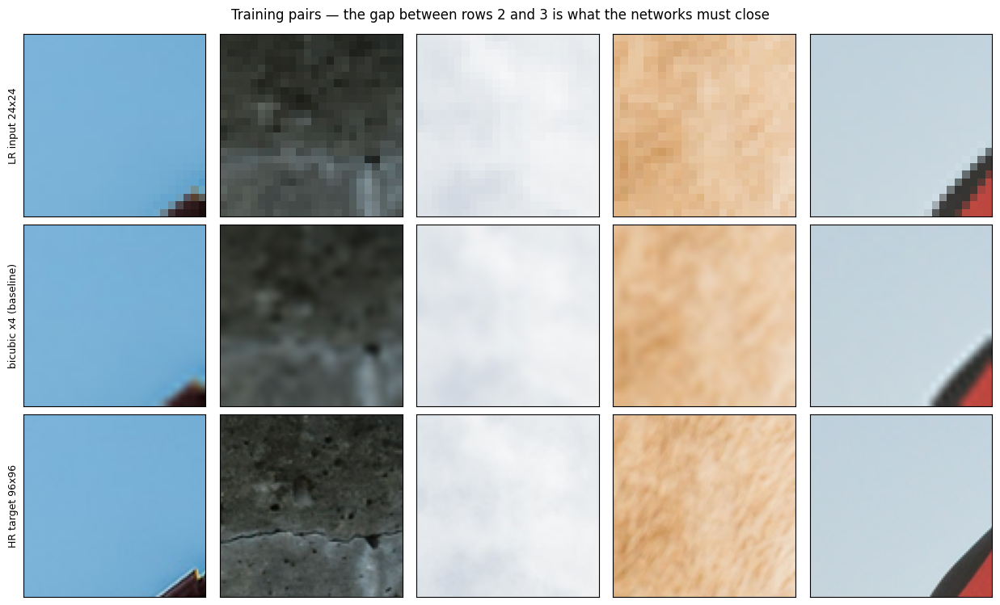

In [5]:
def show_dataset_samples(n=5):
    ds = SRPatchDataset(TRAIN_IMAGES, CFG, train=False)
    n = max(1, min(n, len(ds.files)))          # a small image folder must still work
    fig, axes = plt.subplots(3, n, figsize=(2.5 * n, 7.6), squeeze=False)
    for c in range(n):
        lr, hr = ds[c * ds.per_image]
        up = F.interpolate(lr[None], scale_factor=CFG.scale, mode="bicubic",
                           align_corners=False).clamp(0, 1)[0]
        for r, (t, lab) in enumerate([
                (lr, f"LR input {CFG.lr_patch}x{CFG.lr_patch}"),
                (up, f"bicubic x{CFG.scale} (baseline)"),
                (hr, f"HR target {CFG.hr_patch}x{CFG.hr_patch}")]):
            ax = axes[r, c]
            ax.imshow(t.permute(1, 2, 0).numpy())
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(lab, fontsize=9)
    fig.suptitle(f"Training pairs — the gap between rows 2 and 3 is what the networks must close",
                 fontsize=12)
    plt.tight_layout()
    savefig(fig, "dataset_samples")
    plt.show()


show_dataset_samples()

## 4. Metrics

**PSNR and SSIM follow the standard SR benchmark protocol**, which matters if you want your numbers to be comparable with published results:

1. Convert to the **Y (luma) channel** of YCbCr. The human eye is far more sensitive to luminance than chrominance, and every SR paper reports Y-channel PSNR.
2. **Shave `scale` pixels from each border.** Convolutional models cannot reconstruct edges properly, and including them penalizes all models with a constant that has nothing to do with quality.

RGB PSNR is reported alongside it, since it is what you would compute naively and it is useful to see the two differ.

A caution worth carrying into §16: **PSNR is a per-pixel average, so it rewards blur.** Given uncertainty about a texture, the PSNR-optimal answer is to predict the mean of all plausible textures, which is a smooth grey smear. This is precisely why SRGAN scores badly and still looks better. SSIM is somewhat more structural but shares the bias.

In [6]:
from skimage.metrics import structural_similarity as _ssim


def rgb_to_y(img: np.ndarray) -> np.ndarray:
    """float RGB in [0,1], (H,W,3) -> Y channel in [16,235] (ITU-R BT.601)."""
    return 16.0 + (65.481 * img[..., 0] + 128.553 * img[..., 1] + 24.966 * img[..., 2])


def _prep(t: torch.Tensor, shave: int, y_only: bool):
    a = t.detach().cpu().float().clamp(0, 1).permute(1, 2, 0).numpy()
    if shave:
        a = a[shave:-shave, shave:-shave, :]
    return rgb_to_y(a) if y_only else a * 255.0


def psnr(sr: torch.Tensor, hr: torch.Tensor, shave: int = None, y_only=True) -> float:
    shave = CFG.scale if shave is None else shave
    a, b = _prep(sr, shave, y_only), _prep(hr, shave, y_only)
    mse = float(np.mean((a - b) ** 2))
    return float("inf") if mse == 0 else 10 * math.log10(255.0 ** 2 / mse)


def ssim(sr: torch.Tensor, hr: torch.Tensor, shave: int = None) -> float:
    shave = CFG.scale if shave is None else shave
    a, b = _prep(sr, shave, True), _prep(hr, shave, True)
    return float(_ssim(a, b, data_range=255.0, gaussian_weights=True,
                       sigma=1.5, use_sample_covariance=False))


def count_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


def model_size_mb(m: nn.Module) -> float:
    return (sum(p.numel() * p.element_size() for p in m.parameters())
            + sum(b.numel() * b.element_size() for b in m.buffers())) / 1024 ** 2


@torch.no_grad()
def measure_inference(model, lr_size=None, reps=20, warmup=5) -> float:
    """Milliseconds for one forward pass at a fixed LR resolution."""
    lr_size = lr_size or CFG.lr_patch * 4          # a realistic small-image workload
    model.eval()
    x = torch.randn(1, 3, lr_size, lr_size, device=device)
    for _ in range(warmup):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / reps * 1000


def bicubic_sr(lr: torch.Tensor, scale=None) -> torch.Tensor:
    """The baseline every model must beat."""
    scale = scale or CFG.scale
    return F.interpolate(lr[None], scale_factor=scale, mode="bicubic",
                         align_corners=False).clamp(0, 1)[0]


# sanity check on a known-good case
_a = torch.rand(3, 64, 64)
assert psnr(_a, _a) == float("inf") and abs(ssim(_a, _a) - 1.0) < 1e-6
print("PSNR/SSIM identity check passed (inf dB, SSIM 1.0)")
print(f"bicubic x{CFG.scale} baseline on a val patch: "
      f"PSNR {psnr(bicubic_sr(val_ds[0][0]), val_ds[0][1]):.2f} dB, "
      f"SSIM {ssim(bicubic_sr(val_ds[0][0]), val_ds[0][1]):.4f}")

PSNR/SSIM identity check passed (inf dB, SSIM 1.0)
bicubic x4 baseline on a val patch: PSNR 25.53 dB, SSIM 0.7264


### 4.1 Model summary helper

The assignment asks for a model summary per architecture. This walks the module tree with forward hooks and reports output shape and parameter count per layer, then the totals.

In [7]:
def model_summary(model: nn.Module, name: str, lr_size: int = None, save=True) -> str:
    """torchsummary-style table: layer, output shape, parameters."""
    lr_size = lr_size or CFG.lr_patch
    rows, hooks = [], []

    def hook(mod, inp, out):
        if isinstance(out, torch.Tensor):
            p = sum(q.numel() for q in mod.parameters(recurse=False))
            rows.append((type(mod).__name__, tuple(out.shape[1:]), p))

    for m in model.modules():
        if not list(m.children()):                 # leaf modules only
            hooks.append(m.register_forward_hook(hook))

    was_training = model.training
    model.eval()
    with torch.no_grad():
        dev = next(model.parameters()).device
        out = model(torch.zeros(1, 3, lr_size, lr_size, device=dev))
    for h in hooks:
        h.remove()
    model.train(was_training)

    lines = [f"{name} — input (3, {lr_size}, {lr_size})  ->  output {tuple(out.shape[1:])}",
             f"{'layer':<22}{'output shape':<22}{'params':>12}", "-" * 56]
    for i, (kind, shape, p) in enumerate(rows):
        lines.append(f"{kind + '_' + str(i):<22}{str(shape):<22}{p:12,}")
    lines += ["-" * 56,
              f"{'trainable parameters':<44}{count_params(model):12,}",
              f"{'model size (MB)':<44}{model_size_mb(model):12.2f}",
              f"{'layers with parameters':<44}{sum(1 for r in rows if r[2] > 0):12,}"]
    text = "\n".join(lines)
    print(text)
    if save:
        (RESDIR / f"summary_{name}.txt").write_text(text)
        print(f"  saved -> {RESDIR / f'summary_{name}.txt'}")
    return text

### 4.2 Architecture diagram helper

Draws the block diagrams the assignment asks for. Repeated blocks are collapsed into a single box with a `×N` multiplier, which is how these architectures are drawn in the papers.

In [8]:
BLOCK_COLORS = {
    "input":  "#e9ecef", "conv": "#4c9be8", "act": "#f4a259",
    "res":    "#2a9d8f", "up":   "#e76f51", "norm": "#9d8df1", "output": "#adb5bd",
}


def draw_architecture(blocks, title, filename, skips=(), note=None, box_w=1.0, gap=0.42):
    """blocks: list of (kind, label, sublabel). skips: list of (from_idx, to_idx, label)."""
    n = len(blocks)
    fig_w = max(9.0, n * (box_w + gap) + 1.2)
    fig, ax = plt.subplots(figsize=(fig_w, 3.9 + 0.5 * bool(skips)))
    ax.set_xlim(-0.6, n * (box_w + gap)); ax.set_ylim(-1.15, 1.75)
    ax.axis("off")

    centers = []
    for i, (kind, label, sub) in enumerate(blocks):
        x = i * (box_w + gap)
        ax.add_patch(mpatches.FancyBboxPatch(
            (x, -0.42), box_w, 0.84, boxstyle="round,pad=0.02,rounding_size=0.06",
            facecolor=BLOCK_COLORS.get(kind, "#cccccc"), edgecolor="black", linewidth=.8))
        ax.text(x + box_w / 2, 0.10, label, ha="center", va="center",
                fontsize=8.5, fontweight="bold", wrap=True)
        if sub:
            ax.text(x + box_w / 2, -0.20, sub, ha="center", va="center", fontsize=7)
        centers.append(x + box_w / 2)
        if i < n - 1:
            ax.annotate("", xy=(x + box_w + gap * 0.92, 0), xytext=(x + box_w, 0),
                        arrowprops=dict(arrowstyle="-|>", color="black", lw=1.1))

    for src, dst, lab in skips:
        x0, x1 = centers[src], centers[dst]
        ax.annotate("", xy=(x1, 0.44), xytext=(x0, 0.44),
                    arrowprops=dict(arrowstyle="-|>", color="#c1121f", lw=1.4,
                                    connectionstyle="arc3,rad=-0.32"))
        ax.text((x0 + x1) / 2, 1.32, lab, ha="center", fontsize=8, color="#c1121f")

    if note:
        ax.text(0, -0.95, note, ha="left", fontsize=8, style="italic", color="#333333")
    ax.set_title(title, fontsize=12, fontweight="bold", pad=14)
    plt.tight_layout()
    savefig(fig, filename)
    plt.show()

## 5. Task 1 — SRCNN

The original deep-learning super-resolution network (Dong et al., 2014). Three convolutions, no pooling, no normalization, and — unusually by modern standards — **the upsampling happens first**: the LR image is bicubically interpolated to the target size, and the network then learns to sharpen it.

The paper frames the three layers as an explicit pipeline:

| Layer | Kernel | Role in the paper's framing |
|---|---|---|
| conv1 | 9×9, 64 | patch extraction and representation |
| conv2 | 5×5, 32 | non-linear mapping of LR features to HR features |
| conv3 | 5×5, 3 | reconstruction |

The cost of pre-upsampling is that **every convolution runs at full HR resolution**. At ×4 that is 16× more spatial positions than the LR grid, which is why SRCNN is the slowest network here per parameter — about 69k parameters, but they all operate on the large tensor. Every model after this one moved the upsampling to the end for exactly this reason.

  saved -> sr_outputs\figures\architecture_SRCNN.png


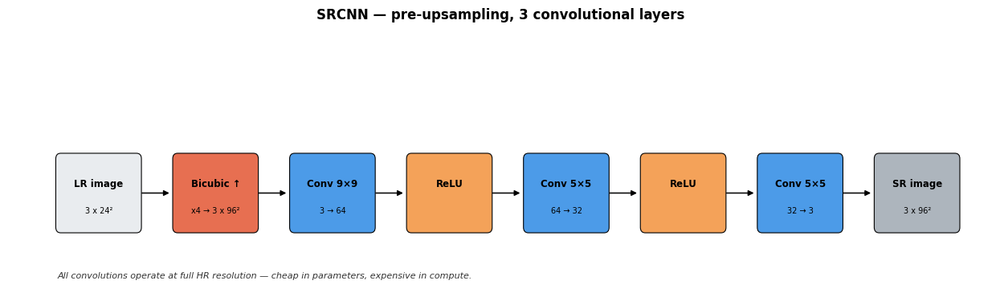

SRCNN — input (3, 24, 24)  ->  output (3, 96, 96)
layer                 output shape                params
--------------------------------------------------------
Conv2d_0              (64, 96, 96)                15,616
Conv2d_1              (32, 96, 96)                51,232
Conv2d_2              (3, 96, 96)                  2,403
--------------------------------------------------------
trainable parameters                              69,251
model size (MB)                                     0.26
layers with parameters                                 3
  saved -> sr_outputs\results\summary_SRCNN.txt


'SRCNN — input (3, 24, 24)  ->  output (3, 96, 96)\nlayer                 output shape                params\n--------------------------------------------------------\nConv2d_0              (64, 96, 96)                15,616\nConv2d_1              (32, 96, 96)                51,232\nConv2d_2              (3, 96, 96)                  2,403\n--------------------------------------------------------\ntrainable parameters                              69,251\nmodel size (MB)                                     0.26\nlayers with parameters                                 3'

In [9]:
class SRCNN(nn.Module):
    """Dong et al. 2014. Pre-upsampling: bicubic first, then 9-5-5 convolutions."""

    def __init__(self, scale=None, channels=3):
        super().__init__()
        self.scale = scale or CFG.scale
        self.conv1 = nn.Conv2d(channels, 64, kernel_size=9, padding=4)
        self.conv2 = nn.Conv2d(64, 32, kernel_size=5, padding=2)
        self.conv3 = nn.Conv2d(32, channels, kernel_size=5, padding=2)

    def forward(self, x):
        # the interpolation is part of the model, so every network in this
        # notebook shares one interface: LR tensor in, HR tensor out
        x = F.interpolate(x, scale_factor=self.scale, mode="bicubic", align_corners=False)
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        return self.conv3(x)


draw_architecture(
    [("input",  "LR image",     f"3 x {CFG.lr_patch}²"),
     ("up",     "Bicubic ↑",    f"x{CFG.scale} → 3 x {CFG.hr_patch}²"),
     ("conv",   "Conv 9×9",     "3 → 64"),
     ("act",    "ReLU",         ""),
     ("conv",   "Conv 5×5",     "64 → 32"),
     ("act",    "ReLU",         ""),
     ("conv",   "Conv 5×5",     "32 → 3"),
     ("output", "SR image",     f"3 x {CFG.hr_patch}²")],
    "SRCNN — pre-upsampling, 3 convolutional layers",
    "architecture_SRCNN",
    note="All convolutions operate at full HR resolution — cheap in parameters, expensive in compute.")

model_summary(SRCNN().to(device), "SRCNN")

## 6. Task 2 — ESPCN

Shi et al., 2016. The key idea is the **sub-pixel convolution** (pixel shuffle): instead of interpolating first, the network works entirely in LR space and produces `C × r²` channels in its final layer, which are then rearranged into a `C × rH × rW` image.

That rearrangement is free — it is a tensor reshape with no parameters and no arithmetic. So ESPCN gets its upsampling essentially for nothing, and every convolution runs on the small LR grid. Compared with SRCNN it uses **fewer parameters and roughly an order of magnitude less compute**, while scoring better.

Every subsequent model in this assignment adopts sub-pixel upsampling. It is the single most important architectural idea in the sequence.

The `tanh` activations are the paper's original choice and are kept here for fidelity; modern reimplementations usually substitute ReLU.

  saved -> sr_outputs\figures\architecture_ESPCN.png


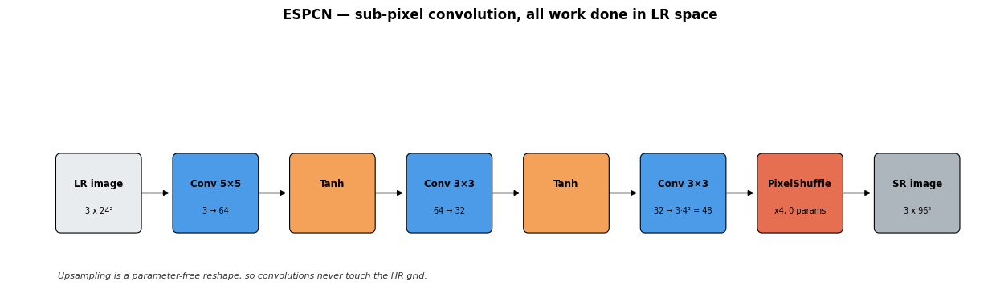

ESPCN — input (3, 24, 24)  ->  output (3, 96, 96)
layer                 output shape                params
--------------------------------------------------------
Conv2d_0              (64, 24, 24)                 4,864
Conv2d_1              (32, 24, 24)                18,464
Conv2d_2              (48, 24, 24)                13,872
PixelShuffle_3        (3, 96, 96)                      0
--------------------------------------------------------
trainable parameters                              37,200
model size (MB)                                     0.14
layers with parameters                                 3
  saved -> sr_outputs\results\summary_ESPCN.txt


'ESPCN — input (3, 24, 24)  ->  output (3, 96, 96)\nlayer                 output shape                params\n--------------------------------------------------------\nConv2d_0              (64, 24, 24)                 4,864\nConv2d_1              (32, 24, 24)                18,464\nConv2d_2              (48, 24, 24)                13,872\nPixelShuffle_3        (3, 96, 96)                      0\n--------------------------------------------------------\ntrainable parameters                              37,200\nmodel size (MB)                                     0.14\nlayers with parameters                                 3'

In [10]:
class ESPCN(nn.Module):
    """Shi et al. 2016. All convolutions in LR space; one pixel-shuffle at the end."""

    def __init__(self, scale=None, channels=3):
        super().__init__()
        self.scale = scale or CFG.scale
        self.conv1 = nn.Conv2d(channels, 64, kernel_size=5, padding=2)
        self.conv2 = nn.Conv2d(64, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, channels * self.scale ** 2, kernel_size=3, padding=1)
        self.shuffle = nn.PixelShuffle(self.scale)

    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = torch.tanh(self.conv2(x))
        return self.shuffle(self.conv3(x))


draw_architecture(
    [("input",  "LR image",       f"3 x {CFG.lr_patch}²"),
     ("conv",   "Conv 5×5",       "3 → 64"),
     ("act",    "Tanh",           ""),
     ("conv",   "Conv 3×3",       "64 → 32"),
     ("act",    "Tanh",           ""),
     ("conv",   "Conv 3×3",       f"32 → 3·{CFG.scale}² = {3*CFG.scale**2}"),
     ("up",     "PixelShuffle",   f"x{CFG.scale}, 0 params"),
     ("output", "SR image",       f"3 x {CFG.hr_patch}²")],
    "ESPCN — sub-pixel convolution, all work done in LR space",
    "architecture_ESPCN",
    note="Upsampling is a parameter-free reshape, so convolutions never touch the HR grid.")

model_summary(ESPCN().to(device), "ESPCN")

## 7. Task 3 — SRResNet

Ledig et al., 2017 — the generator half of the SRGAN paper, trained here on its own with a pixel loss. This is where super-resolution networks get **deep**: 16 residual blocks instead of 3 convolutions.

Two structural ideas carry the depth:

- **Residual blocks** (`conv-BN-PReLU-conv-BN` + identity) let gradients reach early layers, so 16 blocks train as easily as 3 layers would.
- **A global skip connection** from just after the first convolution to just before upsampling. This means the residual trunk only has to learn the *difference* between a blurry upsample and a sharp image, not the image itself. Since LR and HR images are overwhelmingly similar at low frequencies, this is a much easier target.

Upsampling is two stacked `PixelShuffle(2)` stages rather than one `PixelShuffle(4)` — progressive upsampling with a convolution between the stages consistently works better than one large jump.

  saved -> sr_outputs\figures\architecture_SRResNet.png


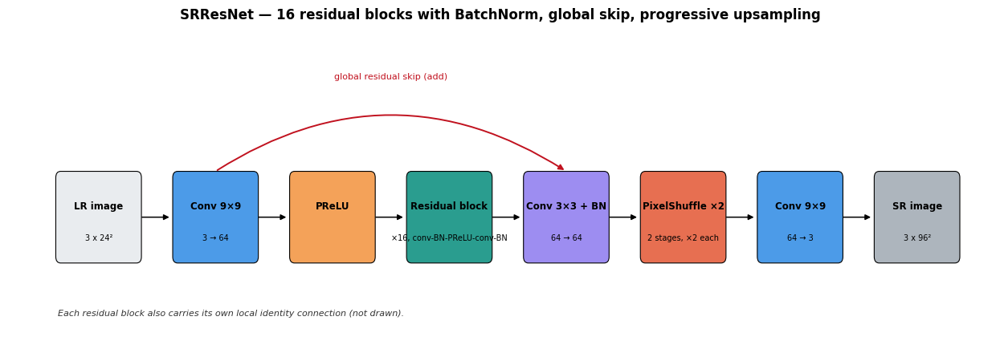

SRResNet — input (3, 24, 24)  ->  output (3, 96, 96)
layer                 output shape                params
--------------------------------------------------------
Conv2d_0              (64, 24, 24)                15,616
PReLU_1               (64, 24, 24)                    64
Conv2d_2              (64, 24, 24)                36,864
BatchNorm2d_3         (64, 24, 24)                   128
PReLU_4               (64, 24, 24)                    64
Conv2d_5              (64, 24, 24)                36,864
BatchNorm2d_6         (64, 24, 24)                   128
Conv2d_7              (64, 24, 24)                36,864
BatchNorm2d_8         (64, 24, 24)                   128
PReLU_9               (64, 24, 24)                    64
Conv2d_10             (64, 24, 24)                36,864
BatchNorm2d_11        (64, 24, 24)                   128
Conv2d_12             (64, 24, 24)                36,864
BatchNorm2d_13        (64, 24, 24)                   128
PReLU_14              (64, 24, 24) 

'SRResNet — input (3, 24, 24)  ->  output (3, 96, 96)\nlayer                 output shape                params\n--------------------------------------------------------\nConv2d_0              (64, 24, 24)                15,616\nPReLU_1               (64, 24, 24)                    64\nConv2d_2              (64, 24, 24)                36,864\nBatchNorm2d_3         (64, 24, 24)                   128\nPReLU_4               (64, 24, 24)                    64\nConv2d_5              (64, 24, 24)                36,864\nBatchNorm2d_6         (64, 24, 24)                   128\nConv2d_7              (64, 24, 24)                36,864\nBatchNorm2d_8         (64, 24, 24)                   128\nPReLU_9               (64, 24, 24)                    64\nConv2d_10             (64, 24, 24)                36,864\nBatchNorm2d_11        (64, 24, 24)                   128\nConv2d_12             (64, 24, 24)                36,864\nBatchNorm2d_13        (64, 24, 24)                   128\nPReLU_14         

In [11]:
class ResidualBlockBN(nn.Module):
    """SRResNet block: conv-BN-PReLU-conv-BN, plus identity."""

    def __init__(self, n_feats=64):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(n_feats, n_feats, 3, padding=1, bias=False),
            nn.BatchNorm2d(n_feats),
            nn.PReLU(n_feats),
            nn.Conv2d(n_feats, n_feats, 3, padding=1, bias=False),
            nn.BatchNorm2d(n_feats),
        )

    def forward(self, x):
        return x + self.body(x)


def make_upsampler(scale, n_feats, activation=None):
    """Progressive sub-pixel upsampling: x4 becomes two x2 stages."""
    layers = []
    if scale in (2, 3):
        factors = [scale]
    elif scale == 4:
        factors = [2, 2]
    else:
        raise ValueError(f"unsupported scale {scale}")
    for f in factors:
        layers += [nn.Conv2d(n_feats, n_feats * f ** 2, 3, padding=1), nn.PixelShuffle(f)]
        if activation is not None:
            layers.append(activation())
    return nn.Sequential(*layers)


class SRResNet(nn.Module):
    def __init__(self, scale=None, n_feats=64, n_blocks=16, channels=3):
        super().__init__()
        self.scale = scale or CFG.scale
        self.head = nn.Sequential(nn.Conv2d(channels, n_feats, 9, padding=4), nn.PReLU(n_feats))
        self.body = nn.Sequential(*[ResidualBlockBN(n_feats) for _ in range(n_blocks)])
        self.body_tail = nn.Sequential(
            nn.Conv2d(n_feats, n_feats, 3, padding=1, bias=False), nn.BatchNorm2d(n_feats))
        self.upsample = make_upsampler(self.scale, n_feats, activation=lambda: nn.PReLU(n_feats))
        self.tail = nn.Conv2d(n_feats, channels, 9, padding=4)

    def forward(self, x):
        x = self.head(x)
        x = x + self.body_tail(self.body(x))      # global residual skip
        return self.tail(self.upsample(x))


draw_architecture(
    [("input",  "LR image",       f"3 x {CFG.lr_patch}²"),
     ("conv",   "Conv 9×9",       "3 → 64"),
     ("act",    "PReLU",          ""),
     ("res",    "Residual block", "×16, conv-BN-PReLU-conv-BN"),
     ("norm",   "Conv 3×3 + BN",  "64 → 64"),
     ("up",     "PixelShuffle ×2","2 stages, ×2 each"),
     ("conv",   "Conv 9×9",       "64 → 3"),
     ("output", "SR image",       f"3 x {CFG.hr_patch}²")],
    "SRResNet — 16 residual blocks with BatchNorm, global skip, progressive upsampling",
    "architecture_SRResNet",
    skips=[(1, 4, "global residual skip (add)")],
    note="Each residual block also carries its own local identity connection (not drawn).")

model_summary(SRResNet().to(device), "SRResNet")

## 8. Task 4 — SRGAN

SRGAN keeps the SRResNet generator and adds two things: a **discriminator** trained to tell real HR patches from generated ones, and a **VGG perceptual loss** measuring distance in a pretrained network's feature space rather than in pixels.

The total generator loss:

```
L_G  =  L_pixel  +  vgg_weight · L_VGG  +  adv_weight · L_adversarial
```

with the defaults from §2 (`6e-3` and `1e-3`). The adversarial weight is small on purpose — the GAN term is a texture prior nudging an already-competent reconstruction, not the main objective.

**Why the perceptual loss is the important part.** Pixel loss has a fundamental problem at ×4: many different plausible HR images are consistent with one LR input, and averaging them is what minimizes MSE. The average of many plausible textures is blur. VGG features are insensitive to exactly which realization of a texture you produce but sensitive to whether it *is* a texture, so optimizing in that space permits a sharp, plausible answer instead of a smeared safe one.

**The generator is initialized from the trained SRResNet**, following the paper. Starting a GAN from random weights is unstable, and this is also why §11 must train SRResNet before SRGAN.

**Expect the PSNR to drop.** Every term SRGAN adds moves it away from the pixel-space optimum. That is the intended trade and it is the heart of the §16 discussion.

  saved -> sr_outputs\figures\architecture_SRGAN.png


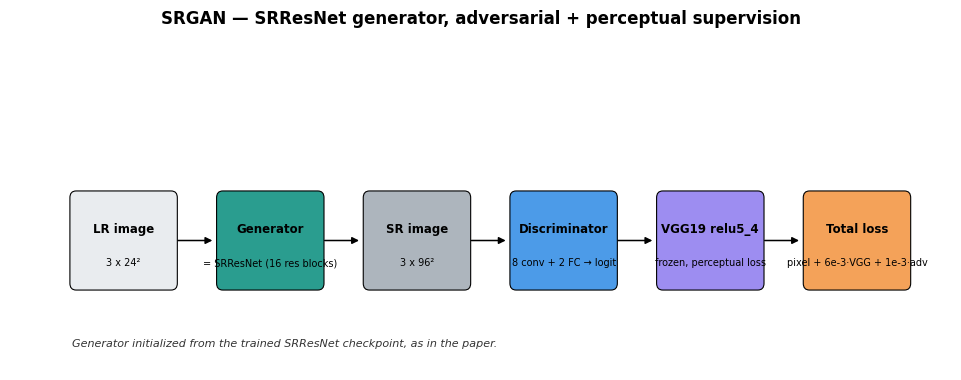

Generator:
SRGAN_generator — input (3, 24, 24)  ->  output (3, 96, 96)
layer                 output shape                params
--------------------------------------------------------
Conv2d_0              (64, 24, 24)                15,616
PReLU_1               (64, 24, 24)                    64
Conv2d_2              (64, 24, 24)                36,864
BatchNorm2d_3         (64, 24, 24)                   128
PReLU_4               (64, 24, 24)                    64
Conv2d_5              (64, 24, 24)                36,864
BatchNorm2d_6         (64, 24, 24)                   128
Conv2d_7              (64, 24, 24)                36,864
BatchNorm2d_8         (64, 24, 24)                   128
PReLU_9               (64, 24, 24)                    64
Conv2d_10             (64, 24, 24)                36,864
BatchNorm2d_11        (64, 24, 24)                   128
Conv2d_12             (64, 24, 24)                36,864
BatchNorm2d_13        (64, 24, 24)                   128
PReLU_14         

'SRGAN_discriminator — input (3, 96, 96)  ->  output (1,)\nlayer                 output shape                params\n--------------------------------------------------------\nConv2d_0              (64, 96, 96)                 1,792\nLeakyReLU_1           (64, 96, 96)                     0\nConv2d_2              (64, 48, 48)                36,864\nBatchNorm2d_3         (64, 48, 48)                   128\nLeakyReLU_4           (64, 48, 48)                     0\nConv2d_5              (128, 48, 48)               73,728\nBatchNorm2d_6         (128, 48, 48)                  256\nLeakyReLU_7           (128, 48, 48)                    0\nConv2d_8              (128, 24, 24)              147,456\nBatchNorm2d_9         (128, 24, 24)                  256\nLeakyReLU_10          (128, 24, 24)                    0\nConv2d_11             (256, 24, 24)              294,912\nBatchNorm2d_12        (256, 24, 24)                  512\nLeakyReLU_13          (256, 24, 24)                    0\nConv2d_14    

In [12]:
class Discriminator(nn.Module):
    """VGG-style binary classifier over HR patches (SRGAN paper, Table 1)."""

    def __init__(self, channels=3, n_feats=64):
        super().__init__()
        def block(cin, cout, stride, bn=True):
            layers = [nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=not bn)]
            if bn:
                layers.append(nn.BatchNorm2d(cout))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.features = nn.Sequential(
            *block(channels,    n_feats,     1, bn=False),
            *block(n_feats,     n_feats,     2),
            *block(n_feats,     n_feats * 2, 1),
            *block(n_feats * 2, n_feats * 2, 2),
            *block(n_feats * 2, n_feats * 4, 1),
            *block(n_feats * 4, n_feats * 4, 2),
            *block(n_feats * 4, n_feats * 8, 1),
            *block(n_feats * 8, n_feats * 8, 2),
        )
        self.pool = nn.AdaptiveAvgPool2d(6)          # any input size -> fixed head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_feats * 8 * 6 * 6, 1024), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, 1),                      # logit; BCEWithLogits applies the sigmoid
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


class VGGFeatureExtractor(nn.Module):
    """Activations of VGG19 relu5_4 — the 'VGG54' loss of the SRGAN paper."""

    def __init__(self, layer_index=36):
        super().__init__()
        weights = tvmodels.VGG19_Weights.IMAGENET1K_V1 if PRETRAINED else None
        vgg = tvmodels.vgg19(weights=weights)
        self.features = nn.Sequential(*list(vgg.features[:layer_index])).eval()
        for p in self.features.parameters():
            p.requires_grad = False
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def train(self, mode=True):
        """Frozen and always in eval mode, so BN/dropout never drift."""
        super().train(False)
        return self

    def forward(self, x):                            # x in [0, 1]
        return self.features((x - self.mean) / self.std)


class SRGANGenerator(SRResNet):
    """Identical to SRResNet; a separate name keeps the two runs distinct in the results."""
    pass


draw_architecture(
    [("input",  "LR image",        f"3 x {CFG.lr_patch}²"),
     ("res",    "Generator",       "= SRResNet (16 res blocks)"),
     ("output", "SR image",        f"3 x {CFG.hr_patch}²"),
     ("conv",   "Discriminator",   "8 conv + 2 FC → logit"),
     ("norm",   "VGG19 relu5_4",   "frozen, perceptual loss"),
     ("act",    "Total loss",      "pixel + 6e-3·VGG + 1e-3·adv")],
    "SRGAN — SRResNet generator, adversarial + perceptual supervision",
    "architecture_SRGAN",
    note="Generator initialized from the trained SRResNet checkpoint, as in the paper.")

print("Generator:")
model_summary(SRGANGenerator().to(device), "SRGAN_generator")
print("\nDiscriminator (operates on HR patches):")
model_summary(Discriminator().to(device), "SRGAN_discriminator", lr_size=CFG.hr_patch)

## 9. Task 5 — EDSR

Lim et al., 2017, winner of the NTIRE 2017 challenge. Architecturally close to SRResNet, and the differences are instructive because **every one of them is a removal**:

| | SRResNet | EDSR |
|---|---|---|
| BatchNorm | yes | **removed** |
| Activation in residual block | PReLU | ReLU |
| Activation after upsampling | PReLU | none |
| Input handling | plain | mean shift (subtract dataset RGB mean) |

**Removing BatchNorm is the central claim.** BN normalizes away the mean and variance of each feature map, but in super-resolution the absolute intensity and contrast of a region *are* the signal — unlike classification, where you only need the object identity and rescaling is harmless. Discarding that information limits the achievable range. Dropping BN also frees roughly 40% of the memory used during training, which is what let the authors build a much wider network at the same cost.

This notebook uses **EDSR-baseline** (16 residual blocks, 64 features) so it is directly comparable with SRResNet at similar capacity. The full paper model is 32 blocks at 256 features and about 43M parameters, far outside a coursework budget.

  saved -> sr_outputs\figures\architecture_EDSR.png


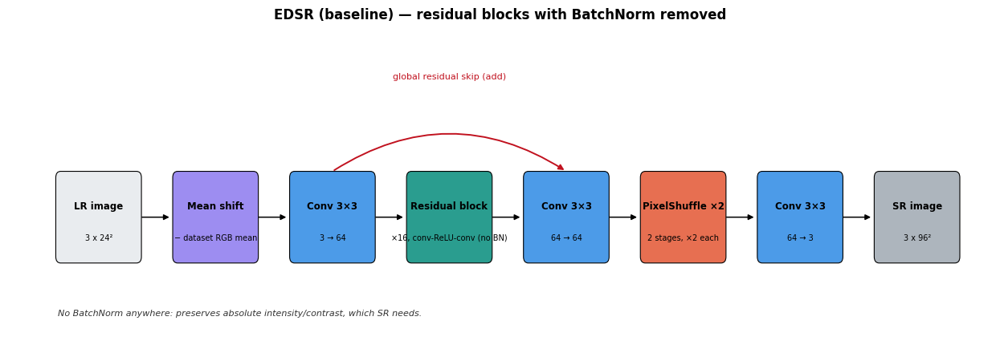

EDSR — input (3, 24, 24)  ->  output (3, 96, 96)
layer                 output shape                params
--------------------------------------------------------
MeanShift_0           (3, 24, 24)                     12
Conv2d_1              (64, 24, 24)                 1,792
Conv2d_2              (64, 24, 24)                36,928
ReLU_3                (64, 24, 24)                     0
Conv2d_4              (64, 24, 24)                36,928
Conv2d_5              (64, 24, 24)                36,928
ReLU_6                (64, 24, 24)                     0
Conv2d_7              (64, 24, 24)                36,928
Conv2d_8              (64, 24, 24)                36,928
ReLU_9                (64, 24, 24)                     0
Conv2d_10             (64, 24, 24)                36,928
Conv2d_11             (64, 24, 24)                36,928
ReLU_12               (64, 24, 24)                     0
Conv2d_13             (64, 24, 24)                36,928
Conv2d_14             (64, 24, 24)     

'EDSR — input (3, 24, 24)  ->  output (3, 96, 96)\nlayer                 output shape                params\n--------------------------------------------------------\nMeanShift_0           (3, 24, 24)                     12\nConv2d_1              (64, 24, 24)                 1,792\nConv2d_2              (64, 24, 24)                36,928\nReLU_3                (64, 24, 24)                     0\nConv2d_4              (64, 24, 24)                36,928\nConv2d_5              (64, 24, 24)                36,928\nReLU_6                (64, 24, 24)                     0\nConv2d_7              (64, 24, 24)                36,928\nConv2d_8              (64, 24, 24)                36,928\nReLU_9                (64, 24, 24)                     0\nConv2d_10             (64, 24, 24)                36,928\nConv2d_11             (64, 24, 24)                36,928\nReLU_12               (64, 24, 24)                     0\nConv2d_13             (64, 24, 24)                36,928\nConv2d_14            

In [13]:
class MeanShift(nn.Conv2d):
    """Subtract (sign=-1) or add back (sign=+1) the dataset RGB mean."""

    def __init__(self, rgb_mean=(0.4488, 0.4371, 0.4040), sign=-1):
        super().__init__(3, 3, kernel_size=1)
        self.weight.data = torch.eye(3).view(3, 3, 1, 1)
        self.bias.data = sign * torch.tensor(rgb_mean)
        for p in self.parameters():
            p.requires_grad = False


class ResidualBlockNoBN(nn.Module):
    """EDSR block: conv-ReLU-conv, no normalization, optional residual scaling."""

    def __init__(self, n_feats=64, res_scale=1.0):
        super().__init__()
        self.res_scale = res_scale
        self.body = nn.Sequential(
            nn.Conv2d(n_feats, n_feats, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(n_feats, n_feats, 3, padding=1),
        )

    def forward(self, x):
        return x + self.body(x) * self.res_scale


class EDSR(nn.Module):
    def __init__(self, scale=None, n_feats=64, n_blocks=16, res_scale=1.0, channels=3):
        super().__init__()
        self.scale = scale or CFG.scale
        self.sub_mean = MeanShift(sign=-1)
        self.add_mean = MeanShift(sign=+1)
        self.head = nn.Conv2d(channels, n_feats, 3, padding=1)
        self.body = nn.Sequential(*[ResidualBlockNoBN(n_feats, res_scale) for _ in range(n_blocks)])
        self.body_tail = nn.Conv2d(n_feats, n_feats, 3, padding=1)
        self.upsample = make_upsampler(self.scale, n_feats, activation=None)
        self.tail = nn.Conv2d(n_feats, channels, 3, padding=1)

    def forward(self, x):
        x = self.sub_mean(x)
        x = self.head(x)
        x = x + self.body_tail(self.body(x))      # global residual skip
        x = self.tail(self.upsample(x))
        return self.add_mean(x)


draw_architecture(
    [("input",  "LR image",        f"3 x {CFG.lr_patch}²"),
     ("norm",   "Mean shift",      "− dataset RGB mean"),
     ("conv",   "Conv 3×3",        "3 → 64"),
     ("res",    "Residual block",  "×16, conv-ReLU-conv (no BN)"),
     ("conv",   "Conv 3×3",        "64 → 64"),
     ("up",     "PixelShuffle ×2", "2 stages, ×2 each"),
     ("conv",   "Conv 3×3",        "64 → 3"),
     ("output", "SR image",        f"3 x {CFG.hr_patch}²")],
    "EDSR (baseline) — residual blocks with BatchNorm removed",
    "architecture_EDSR",
    skips=[(2, 4, "global residual skip (add)")],
    note="No BatchNorm anywhere: preserves absolute intensity/contrast, which SR needs.")

model_summary(EDSR().to(device), "EDSR")

## 10. Model registry

In [14]:
MODELS: Dict[str, type] = {
    "SRCNN":    SRCNN,
    "ESPCN":    ESPCN,
    "SRResNet": SRResNet,
    "SRGAN":    SRGANGenerator,
    "EDSR":     EDSR,
}
MODEL_ORDER = list(MODELS)
METHOD_ORDER = ["Bicubic"] + MODEL_ORDER          # bicubic baseline first in every table
COLORS = dict(zip(METHOD_ORDER, ["#8d99ae", "#4c9be8", "#f4a259", "#2a9d8f", "#c1121f", "#9d8df1"]))

print(f"{'Model':<12}{'Parameters':>13}{'Size (MB)':>12}{'Inference (ms)':>17}")
print("-" * 54)
ARCH_STATS = {}
for name, ctor in MODELS.items():
    m = ctor().to(device)
    ARCH_STATS[name] = dict(params=count_params(m), size_mb=model_size_mb(m),
                            infer_ms=measure_inference(m, reps=5, warmup=2))
    s = ARCH_STATS[name]
    print(f"{name:<12}{s['params']:13,}{s['size_mb']:12.2f}{s['infer_ms']:17.2f}")
    del m
if device.type == "cuda":
    torch.cuda.empty_cache()

Model          Parameters   Size (MB)   Inference (ms)
------------------------------------------------------
SRCNN              69,251        0.26             2.42
ESPCN              37,200        0.14             0.28
SRResNet        1,548,547        5.92            12.01
SRGAN           1,548,547        5.92            13.32
EDSR            1,517,571        5.79             5.23


## 11. Training

One loop for SRCNN, ESPCN, SRResNet and EDSR — **L1 pixel loss, Adam, linear warmup then cosine decay** — but each network runs at **its own learning rate and epoch count**, set in `MODEL_HP` in §2. SRGAN gets a separate loop, because a GAN cannot share a recipe with a regression model.

Checkpoint selection is on **validation PSNR**, never on the test set.

### Where the learning rates come from

Not from taste — from a sweep. Each pixel-loss model was trained at every rate in {1e-3, 5e-4, 2e-4, 2e-3} on this data at a reduced budget (32 patches per image, 15 epochs ≈ 2,400 steps) and scored on the same validation patches:

| model | 4e-3 | 2e-3 | 1e-3 | 5e-4 | 2e-4 | chosen |
|---|---|---|---|---|---|---|
| SRCNN | — | 31.31 | **31.43** | 31.38 | 31.30 | 1e-3 |
| ESPCN | 31.14 | 31.12 | 31.04 | 30.82 | 30.28 | 2e-3 |
| SRResNet | — | 31.44 | **31.50** | 31.33 | 31.03 | 1e-3 |
| EDSR | — | 31.85 | **31.92** | 31.85 | 31.55 | 1e-3 |

Best validation PSNR (dB) reached inside the probe budget; — means not run.

Three of the four peak at 1e-3 with the optimum *interior* to the grid, so that choice is settled. **ESPCN is the exception**: the smallest network here at 37k parameters, it keeps improving as the rate rises, which is the usual behaviour of small models. It is set to 2e-3 rather than the nominally best 4e-3 because that last margin is 0.02 dB — well under the ~0.1 dB this notebook calls interpretable — and a short sweep systematically flatters high learning rates relative to a run ten times longer.

SRGAN is not swept. It stays at 1e-4 for both generator and discriminator, where stability matters more than convergence speed.

**Two departures from the base config are worth naming.** L1 rather than the MSE of the original SRCNN/ESPCN papers, because it converges better and one loss across the four keeps the pixel-loss group comparable. And **warmup on SRResNet and EDSR only**: their learning rate ramps from zero over the first 3% of steps, since at a high peak rate the first few hundred updates are the ones most likely to destabilize a 16-block residual trunk — EDSR especially, which has no BatchNorm to rescue it.

### Training budget — read this before you run

The single thing that determines whether your numbers mean anything is the **total number of gradient steps**, printed in §3.1. At the current settings (DIV2K-train, 640 training images, 10 patches per image, 60 epochs) that is **24,000 steps per model** — the same step count the 100-image configuration gave at 80 patches per image, but every step now draws its crops from eight times as many distinct photographs. More data at equal compute is close to free generalization; more *steps* is the next lever, and the one this budget has not spent.

For calibration: the original papers train for 10⁵–10⁶ updates, so this is still one to two orders of magnitude short and every absolute number here sits below published results. At a few hundred steps every network scores *below* bicubic, because it has barely moved from its random initialization — an untrained network outputs near-zero, worth about 7 dB. If your results table shows all five models losing to bicubic, the cause is almost always budget, not a broken model.

If your results look weak, raise `CFG.epochs` or `CFG.patches_per_image` first — both scale the step count linearly — before changing anything architectural. Note that the swept learning rates were chosen at this budget; a much longer run generally wants a lower peak rate, so re-run the sweep if you change the budget substantially.


In [15]:
def make_model(name):
    torch.manual_seed(SEED)                       # identical init for every run
    return MODELS[name]().to(device)


def hp_for(name) -> dict:
    """Per-model hyperparameters from §2, falling back to the shared defaults."""
    hp = dict(lr=CFG.lr, epochs=CFG.epochs, warmup=0.0)
    hp.update(MODEL_HP.get(name, {}))
    return hp


def make_scheduler(opt, epochs, warmup, steps_per_epoch):
    """Linear warmup over the first `warmup` fraction of steps, then cosine decay.

    Stepped once per batch rather than once per epoch: warmup only means
    anything at step granularity, and the cosine comes out smoother for free.
    """
    total = max(1, epochs * steps_per_epoch)
    warm = int(total * warmup)

    def factor(step):
        if step < warm:                            # ramp 0 -> 1
            return (step + 1) / max(1, warm)
        p = (step - warm) / max(1, total - warm)   # decay 1 -> 0
        return 0.5 * (1.0 + math.cos(math.pi * min(p, 1.0)))

    return torch.optim.lr_scheduler.LambdaLR(opt, factor)


@torch.no_grad()
def evaluate_val(model, criterion):
    """Pixel loss and Y-channel PSNR over the fixed validation patches."""
    model.eval()
    loss_sum, psnr_sum, n = 0.0, 0.0, 0
    for lr, hr in val_loader:
        lr, hr = lr.to(device), hr.to(device)
        sr = model(lr)
        loss_sum += criterion(sr, hr).item() * lr.size(0)
        sr_c = sr.clamp(0, 1)
        for i in range(lr.size(0)):
            psnr_sum += psnr(sr_c[i], hr[i])
        n += lr.size(0)
    return loss_sum / n, psnr_sum / n


def train_sr(name, epochs=None, lr=None, warmup=None, verbose=True):
    """Shared loop for the four pixel-loss models, per-model hyperparameters."""
    hp = hp_for(name)
    epochs = hp["epochs"] if epochs is None else epochs
    lr = hp["lr"] if lr is None else lr
    warmup = hp["warmup"] if warmup is None else warmup

    model = make_model(name)
    criterion = nn.L1Loss()
    opt = torch.optim.Adam(model.parameters(), lr=lr, betas=CFG.betas)
    sched = make_scheduler(opt, epochs, warmup, len(train_loader))

    hist = {"train_loss": [], "train_pixel": [], "val_loss": [], "val_psnr": [],
            "lr": [], "epoch_time": []}
    best_psnr, best_state = -1.0, None
    t0 = time.time()

    for ep in range(1, epochs + 1):
        te = time.time()
        model.train()
        run, n = 0.0, 0
        for lr_b, hr_b in train_loader:
            lr_b, hr_b = lr_b.to(device), hr_b.to(device)
            opt.zero_grad(set_to_none=True)
            loss = criterion(model(lr_b), hr_b)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()                          # per batch, so warmup resolves
            run += loss.item() * lr_b.size(0); n += lr_b.size(0)

        tr = run / n
        vl, vp = evaluate_val(model, criterion)
        hist["train_loss"].append(tr);  hist["train_pixel"].append(tr)
        hist["val_loss"].append(vl);    hist["val_psnr"].append(vp)
        hist["lr"].append(opt.param_groups[0]["lr"])
        hist["epoch_time"].append(time.time() - te)

        if vp > best_psnr:
            best_psnr = vp
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"  epoch {ep:3d}/{epochs} | train L1 {tr:.5f} | val L1 {vl:.5f} | "
                  f"val PSNR {vp:6.3f} dB | lr {opt.param_groups[0]['lr']:.2e} | "
                  f"{hist['epoch_time'][-1]:.1f}s")

    model.load_state_dict(best_state)
    torch.save(best_state, MODELDIR / f"{name}.pth")
    return {"model": model, "history": hist, "train_time_s": time.time() - t0,
            "best_val_psnr": best_psnr, "epochs": epochs,
            "hparams": dict(lr=lr, epochs=epochs, warmup=warmup)}


def train_srgan(epochs=None, lr=None, verbose=True):
    """Generator + discriminator + VGG perceptual loss, initialized from SRResNet."""
    hp = hp_for("SRGAN")
    epochs = hp["epochs"] if epochs is None else epochs
    lr = hp["lr"] if lr is None else lr

    G = make_model("SRGAN")
    D = Discriminator().to(device)
    vgg = VGGFeatureExtractor().to(device)

    ckpt = MODELDIR / "SRResNet.pth"
    if ckpt.exists():
        G.load_state_dict(torch.load(ckpt, map_location=device))
        print("  generator initialized from the trained SRResNet checkpoint")
    else:
        print("  WARNING: no SRResNet checkpoint found — starting the generator from scratch. "
              "GAN training is much less stable this way; train SRResNet first.")

    pixel_l = nn.L1Loss()
    feat_l  = nn.MSELoss()
    bce     = nn.BCEWithLogitsLoss()
    optG = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.9, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.9, 0.999))
    schedG = make_scheduler(optG, epochs, 0.0, len(train_loader))
    schedD = make_scheduler(optD, epochs, 0.0, len(train_loader))

    hist = {"train_loss": [], "train_pixel": [], "val_loss": [], "val_psnr": [],
            "d_loss": [], "adv_loss": [], "vgg_loss": [], "lr": [], "epoch_time": []}
    best_psnr, best_state = -1.0, None
    t0 = time.time()

    for ep in range(1, epochs + 1):
        te = time.time()
        G.train(); D.train()
        acc = dict(g=0.0, d=0.0, px=0.0, adv=0.0, vgg=0.0); n = 0

        for lr_b, hr_b in train_loader:
            lr_b, hr_b = lr_b.to(device), hr_b.to(device)
            b = lr_b.size(0)
            real_t = torch.ones (b, 1, device=device) * 0.9   # one-sided label smoothing
            fake_t = torch.zeros(b, 1, device=device)

            # ---- discriminator ----
            sr = G(lr_b)
            optD.zero_grad(set_to_none=True)
            d_loss = bce(D(hr_b), real_t) + bce(D(sr.detach()), fake_t)
            d_loss.backward()
            optD.step()

            # ---- generator ----
            optG.zero_grad(set_to_none=True)
            l_px  = pixel_l(sr, hr_b)
            l_vgg = feat_l(vgg(sr.clamp(0, 1)), vgg(hr_b))
            l_adv = bce(D(sr), torch.ones(b, 1, device=device))
            g_loss = l_px + CFG.vgg_weight * l_vgg + CFG.adv_weight * l_adv
            g_loss.backward()
            torch.nn.utils.clip_grad_norm_(G.parameters(), 1.0)
            optG.step()
            schedG.step(); schedD.step()

            for k, v in zip("g d px adv vgg".split(),
                            [g_loss, d_loss, l_px, l_adv, l_vgg]):
                acc[k] += v.item() * b
            n += b

        vl, vp = evaluate_val(G, pixel_l)
        hist["train_loss"].append(acc["g"] / n);   hist["train_pixel"].append(acc["px"] / n)
        hist["d_loss"].append(acc["d"] / n);       hist["adv_loss"].append(acc["adv"] / n)
        hist["vgg_loss"].append(acc["vgg"] / n)
        hist["val_loss"].append(vl);               hist["val_psnr"].append(vp)
        hist["lr"].append(optG.param_groups[0]["lr"])
        hist["epoch_time"].append(time.time() - te)

        if vp > best_psnr:
            best_psnr = vp
            best_state = {k: v.detach().cpu().clone() for k, v in G.state_dict().items()}
        if verbose:
            print(f"  epoch {ep:3d}/{epochs} | G {acc['g']/n:.4f} (px {acc['px']/n:.4f}, "
                  f"vgg {acc['vgg']/n:.3f}, adv {acc['adv']/n:.3f}) | D {acc['d']/n:.4f} | "
                  f"val PSNR {vp:6.3f} dB | {hist['epoch_time'][-1]:.1f}s")

    G.load_state_dict(best_state)
    torch.save(best_state, MODELDIR / "SRGAN.pth")
    del D, vgg
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return {"model": G, "history": hist, "train_time_s": time.time() - t0,
            "best_val_psnr": best_psnr, "epochs": epochs,
            "hparams": dict(lr=lr, epochs=epochs, warmup=0.0)}


## 12. Run training and plot the loss curves

SRResNet is trained **before** SRGAN because the GAN generator is initialized from its weights.

Budget: on a GPU expect roughly 30–60 minutes in total at the default settings, with SRGAN the most expensive per epoch (three networks in the loop). On CPU, set `QUICK_MODE = True` in §1 — the full run is not practical.

In [16]:
TRAINED, HISTORY = {}, {}

for name in MODEL_ORDER:                           # SRGAN comes after SRResNet by construction
    hp = hp_for(name)
    print(f"\n{'='*70}\nTraining {name}  |  lr {hp['lr']:g} | {hp['epochs']} epochs | "
          f"warmup {hp['warmup']:.0%}\n{'='*70}")
    res = train_srgan() if name == "SRGAN" else train_sr(name)
    TRAINED[name] = res["model"]
    HISTORY[name] = res
    print(f"  -> best val PSNR {res['best_val_psnr']:.3f} dB | "
          f"{res['train_time_s']:.0f}s | {ARCH_STATS[name]['params']:,} params")

with open(RESDIR / "training_history.json", "w") as f:
    json.dump({k: {"history": v["history"], "train_time_s": v["train_time_s"],
                   "best_val_psnr": v["best_val_psnr"], "epochs": v["epochs"],
                   "hparams": v.get("hparams", {})}
               for k, v in HISTORY.items()}, f, indent=2)
print(f"\nsaved -> {RESDIR / 'training_history.json'}")



Training SRCNN  |  lr 0.001 | 60 epochs | warmup 0%
  epoch   1/60 | train L1 0.05662 | val L1 0.04534 | val PSNR 30.373 dB | lr 9.99e-04 | 38.6s
  epoch   2/60 | train L1 0.03949 | val L1 0.03826 | val PSNR 31.223 dB | lr 9.97e-04 | 5.3s
  epoch   3/60 | train L1 0.03534 | val L1 0.03445 | val PSNR 31.562 dB | lr 9.94e-04 | 5.1s
  epoch   4/60 | train L1 0.03651 | val L1 0.03559 | val PSNR 32.265 dB | lr 9.89e-04 | 5.1s
  epoch   5/60 | train L1 0.03411 | val L1 0.03782 | val PSNR 30.326 dB | lr 9.83e-04 | 5.1s
  epoch   6/60 | train L1 0.03388 | val L1 0.03596 | val PSNR 30.998 dB | lr 9.76e-04 | 5.1s
  epoch   7/60 | train L1 0.03306 | val L1 0.03204 | val PSNR 32.705 dB | lr 9.67e-04 | 5.1s
  epoch   8/60 | train L1 0.03297 | val L1 0.03385 | val PSNR 32.375 dB | lr 9.57e-04 | 5.2s
  epoch   9/60 | train L1 0.03240 | val L1 0.03402 | val PSNR 32.412 dB | lr 9.46e-04 | 5.1s
  epoch  10/60 | train L1 0.03178 | val L1 0.03382 | val PSNR 30.806 dB | lr 9.33e-04 | 5.1s
  epoch  11/60 |

  saved -> sr_outputs\figures\loss_curves_SRCNN.png


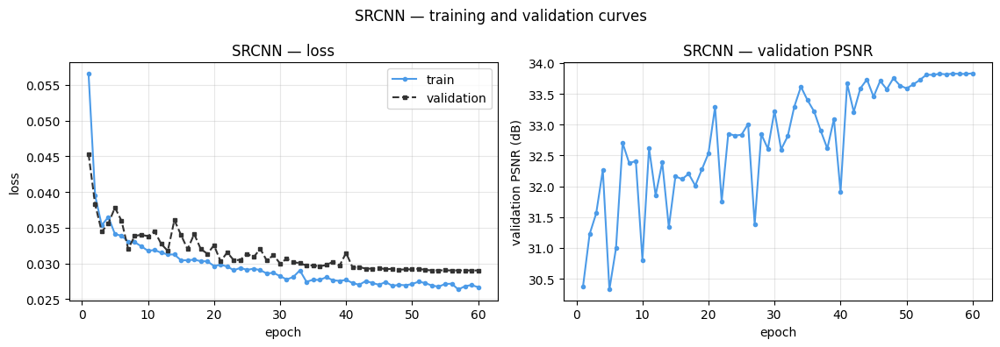

  saved -> sr_outputs\figures\loss_curves_ESPCN.png


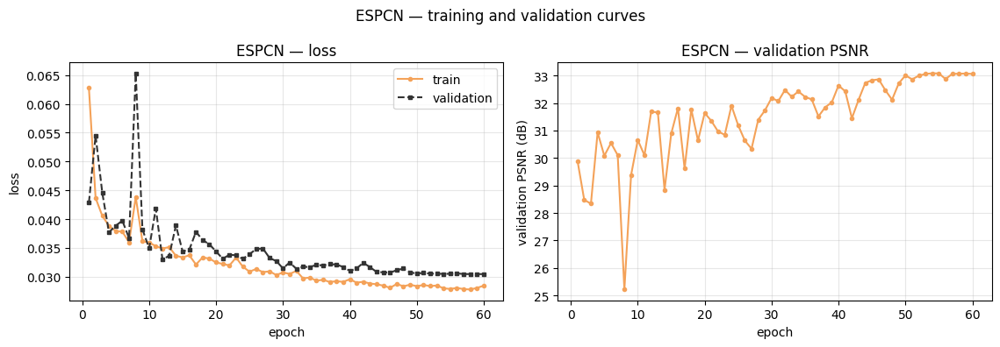

  saved -> sr_outputs\figures\loss_curves_SRResNet.png


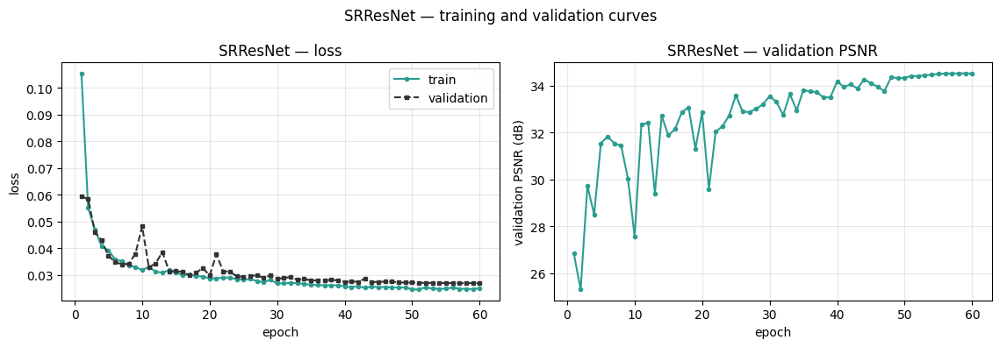

  saved -> sr_outputs\figures\loss_curves_SRGAN.png


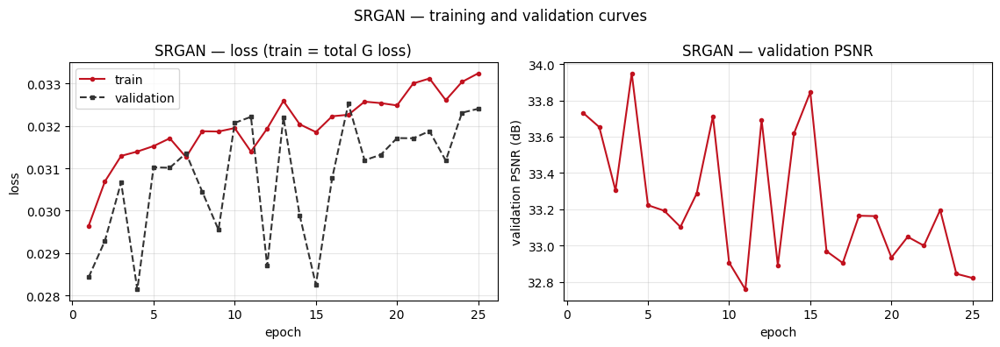

  saved -> sr_outputs\figures\loss_curves_EDSR.png


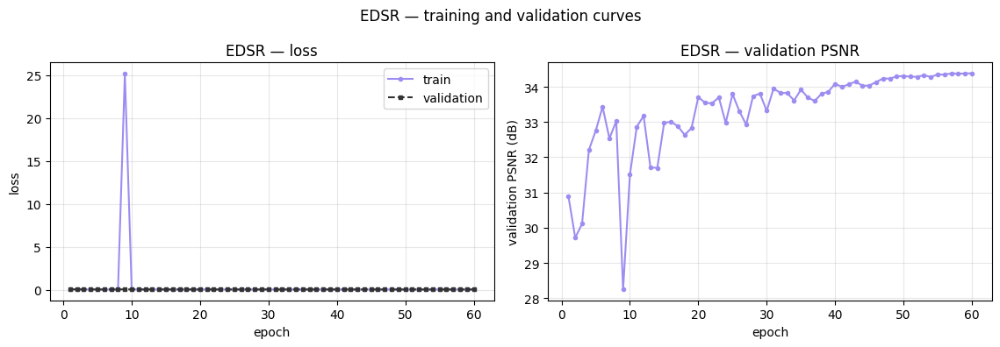

In [17]:
# --- per-model training/validation loss curves (one figure per model, as the tasks ask) ---
for name in MODEL_ORDER:
    h = HISTORY[name]["history"]
    ep = range(1, len(h["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))

    axes[0].plot(ep, h["train_loss"], "-o", ms=3, color=COLORS[name], label="train")
    axes[0].plot(ep, h["val_loss"], "--s", ms=3, color="#333333", label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
    axes[0].set_title(f"{name} — loss" + (" (train = total G loss)" if name == "SRGAN" else ""))
    axes[0].legend(); axes[0].grid(alpha=.3)

    axes[1].plot(ep, h["val_psnr"], "-o", ms=3, color=COLORS[name])
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation PSNR (dB)")
    axes[1].set_title(f"{name} — validation PSNR"); axes[1].grid(alpha=.3)

    fig.suptitle(f"{name} — training and validation curves", fontsize=12)
    plt.tight_layout()
    savefig(fig, f"loss_curves_{name}")
    plt.show()

  saved -> sr_outputs\figures\loss_curves_all.png


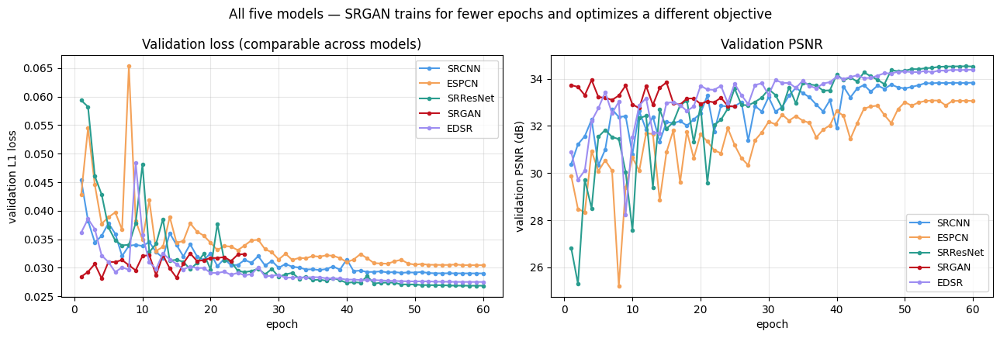

In [18]:
# --- all models on shared axes ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for name in MODEL_ORDER:
    h = HISTORY[name]["history"]
    ep = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], "-o", ms=3, color=COLORS[name], label=name)
    axes[1].plot(ep, h["val_psnr"], "-o", ms=3, color=COLORS[name], label=name)
axes[0].set_ylabel("validation L1 loss"); axes[0].set_title("Validation loss (comparable across models)")
axes[1].set_ylabel("validation PSNR (dB)"); axes[1].set_title("Validation PSNR")
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=9)
fig.suptitle("All five models — SRGAN trains for fewer epochs and optimizes a different objective",
             fontsize=12)
plt.tight_layout()
savefig(fig, "loss_curves_all")
plt.show()

## 13. Test results on held-out images

These images were never used for training patches or validation. Each is cropped to a multiple of the scale factor, bicubically downsampled to produce the LR input, then reconstructed by every model.

Each figure shows the full reconstruction on the top row and a **magnified crop on the bottom row**. The crop is chosen automatically as the region of highest gradient energy in the HR image, because that is where the models actually differ — in flat sky or a blurred background every method looks identical, and a comparison that only shows those regions tells you nothing.

  saved -> sr_outputs\figures\testset_01_0733.png


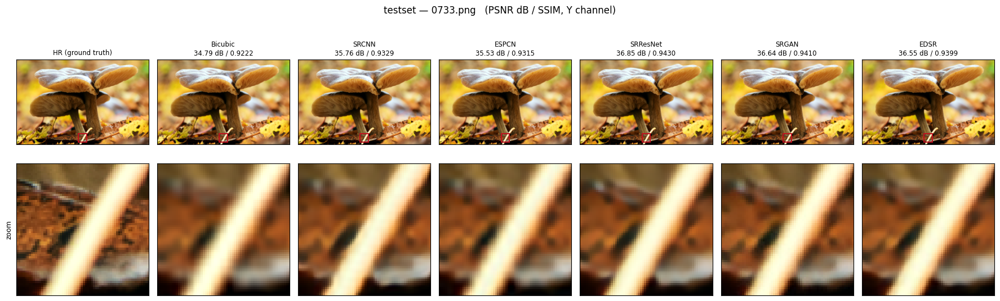

  saved -> sr_outputs\figures\testset_02_0375.png


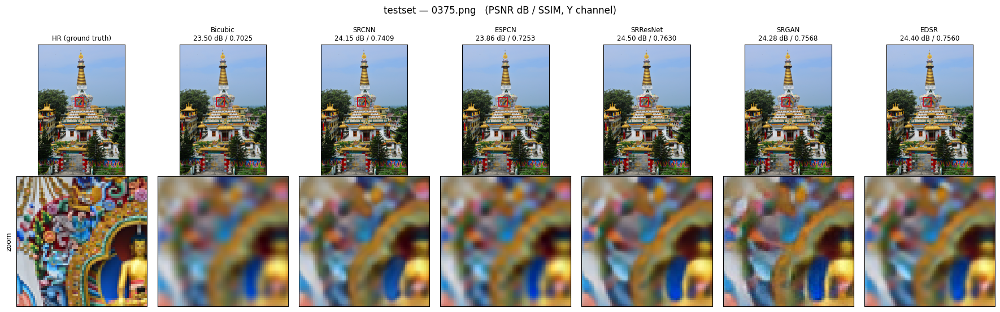

  saved -> sr_outputs\figures\testset_03_0574.png


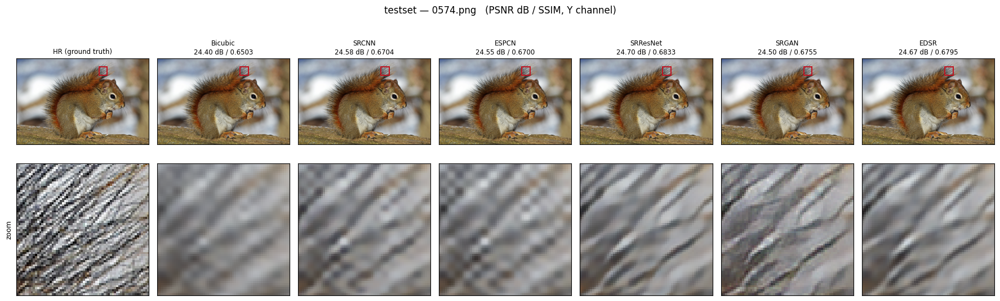

  saved -> sr_outputs\figures\testset_04_0491.png


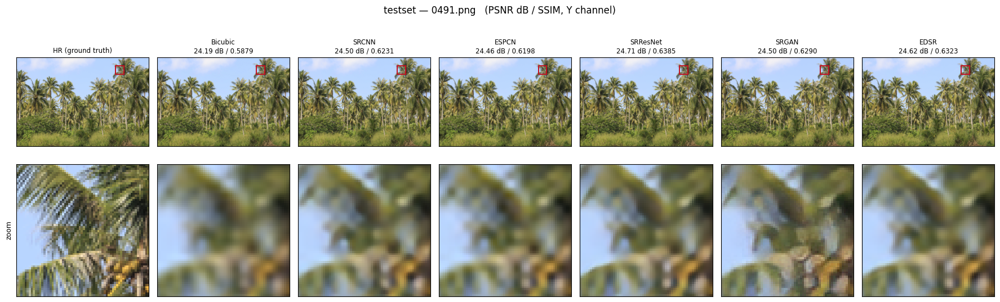

  saved -> sr_outputs\figures\testset_05_0648.png


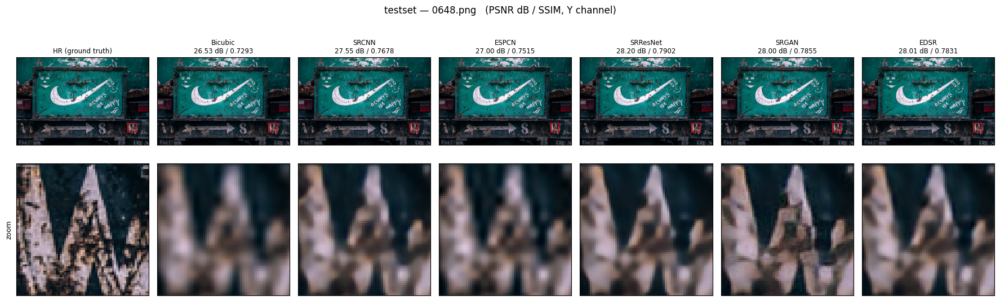

  saved -> sr_outputs\figures\testset_06_0532.png


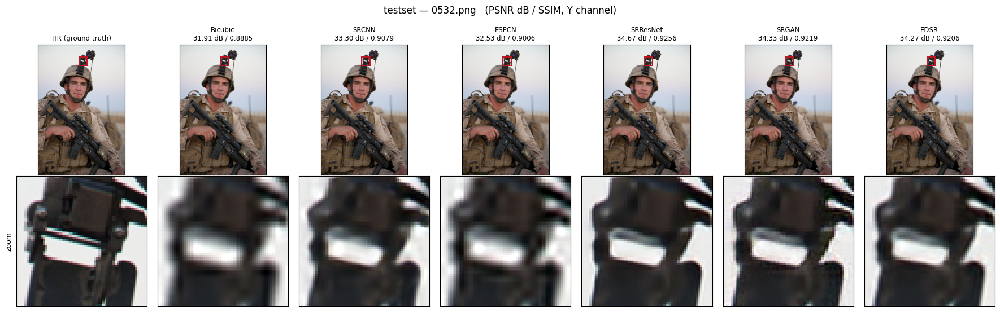

  saved -> sr_outputs\figures\testset_07_0359.png


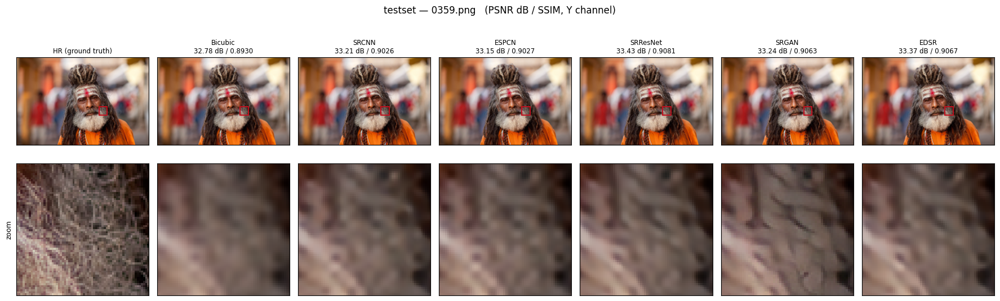

  saved -> sr_outputs\figures\testset_08_0650.png


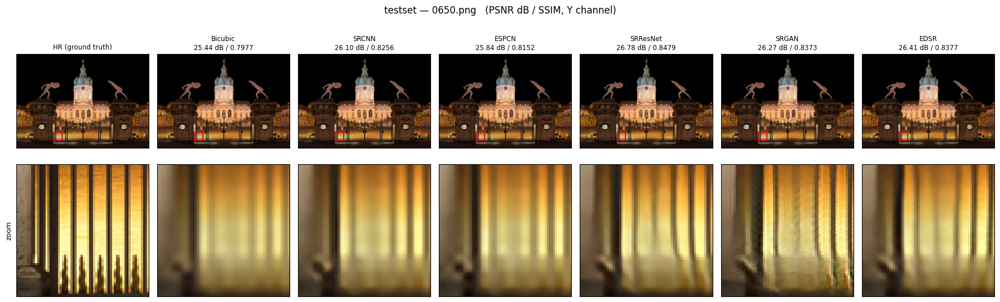

  saved -> sr_outputs\figures\testset_09_0451.png


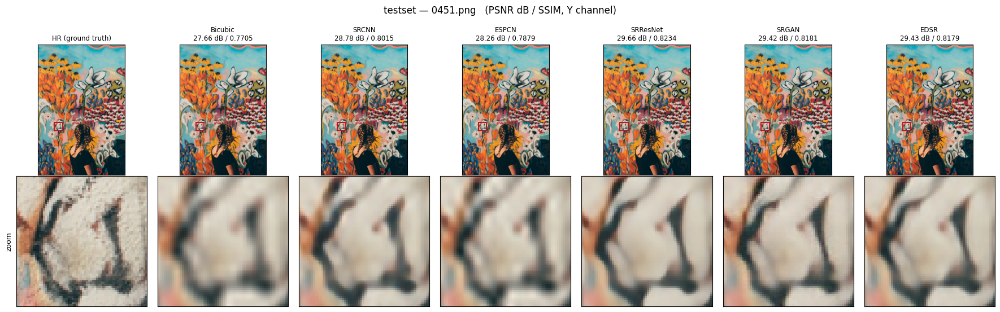

  saved -> sr_outputs\figures\testset_10_0774.png


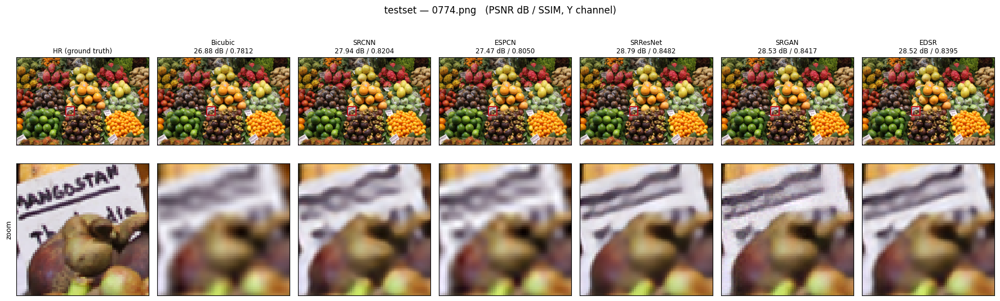


480 records over 80 held-out images (10 of them with saved figures)


In [19]:
@torch.no_grad()
def sr_infer(model, lr_t: torch.Tensor) -> Tuple[torch.Tensor, float]:
    """LR (3,h,w) in [0,1] -> SR (3,H,W) in [0,1], plus elapsed milliseconds."""
    model.eval()
    x = lr_t[None].to(device)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    out = model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    ms = (time.perf_counter() - t0) * 1000
    return out[0].clamp(0, 1).cpu(), ms


def load_hr(path: Path, max_side: int = None) -> Image.Image:
    """Open, optionally shrink very large photographs, crop to a multiple of the scale."""
    max_side = max_side or CFG.max_hr_side
    img = Image.open(path).convert("RGB")
    if max(img.size) > max_side:
        r = max_side / max(img.size)
        img = img.resize((max(1, int(img.width * r)), max(1, int(img.height * r))), Image.BICUBIC)
    return crop_to_multiple(img, CFG.scale)


def best_crop_box(hr_t: torch.Tensor, size=64):
    """Region of highest gradient energy — where the models visibly differ."""
    g = hr_t.mean(0)
    gx = (g[:, 1:] - g[:, :-1]).abs()
    gy = (g[1:, :] - g[:-1, :]).abs()
    energy = F.pad(gx, (0, 1)) + F.pad(gy, (0, 0, 0, 1))
    H, W = energy.shape
    size = min(size, H, W)
    pooled = F.avg_pool2d(energy[None, None], kernel_size=size, stride=max(1, size // 2))[0, 0]
    iy, ix = np.unravel_index(int(pooled.argmax()), pooled.shape)
    step = max(1, size // 2)
    y, x = min(iy * step, H - size), min(ix * step, W - size)
    return int(x), int(y), int(size)


def evaluate_image_set(paths: List[Path], tag: str, make_figures=True,
                       max_figures=None) -> List[dict]:
    """Run bicubic + all five models over a list of HR images; save comparisons.

    Metrics are computed for every image. `max_figures` limits how many of them
    also get a saved comparison panel — with an 80-image test split the figures
    are the expensive part and a report only needs a handful.
    """
    records = []
    for k, path in enumerate(paths):
        hr_img = load_hr(path)
        lr_img = bicubic_down(hr_img, CFG.scale)
        hr_t, lr_t = pil_to_tensor(hr_img), pil_to_tensor(lr_img)

        outputs = {"Bicubic": bicubic_sr(lr_t)}
        times   = {"Bicubic": float("nan")}
        for name in MODEL_ORDER:
            outputs[name], times[name] = sr_infer(TRAINED[name], lr_t)

        for method, sr_t in outputs.items():
            records.append(dict(image=path.name, set=tag, method=method,
                                psnr_y=psnr(sr_t, hr_t), ssim_y=ssim(sr_t, hr_t),
                                psnr_rgb=psnr(sr_t, hr_t, y_only=False),
                                time_ms=times[method],
                                hr_size=f"{hr_img.width}x{hr_img.height}"))

        if make_figures and (max_figures is None or k < max_figures):
            x, y, s = best_crop_box(hr_t)
            panels = [("HR (ground truth)", hr_t)] + \
                     [(m, outputs[m]) for m in METHOD_ORDER]
            fig, axes = plt.subplots(2, len(panels), figsize=(2.55 * len(panels), 5.6))
            for c, (label, t) in enumerate(panels):
                axes[0, c].imshow(t.permute(1, 2, 0).numpy())
                axes[0, c].add_patch(plt.Rectangle((x, y), s, s, ec="#c1121f", fc="none", lw=1.4))
                sub = "" if label == "HR (ground truth)" else \
                    f"\n{psnr(t, hr_t):.2f} dB / {ssim(t, hr_t):.4f}"
                axes[0, c].set_title(label + sub, fontsize=8.5)
                axes[1, c].imshow(t[:, y:y + s, x:x + s].permute(1, 2, 0).numpy(),
                                  interpolation="nearest")
                for ax in (axes[0, c], axes[1, c]):
                    ax.set_xticks([]); ax.set_yticks([])
            axes[1, 0].set_ylabel("zoom", fontsize=9)
            fig.suptitle(f"{tag} — {path.name}   (PSNR dB / SSIM, Y channel)", fontsize=12)
            plt.tight_layout()
            savefig(fig, f"{tag}_{k+1:02d}_{path.stem}")
            plt.show()
    return records


TEST_FIGURES = 10          # metrics over every test image, panels for the first few
test_records = evaluate_image_set(TEST_IMAGES, "testset", max_figures=TEST_FIGURES)
print(f"\n{len(test_records)} records over {len(TEST_IMAGES)} held-out images "
f"({min(TEST_FIGURES, len(TEST_IMAGES))} of them with saved figures)")

In [20]:
def aggregate(records, tag):
    """Mean metrics per method, printed and written to CSV."""
    methods = METHOD_ORDER
    agg = {}
    for m in methods:
        rs = [r for r in records if r["method"] == m]
        agg[m] = dict(
            psnr_y=float(np.mean([r["psnr_y"] for r in rs])),
            ssim_y=float(np.mean([r["ssim_y"] for r in rs])),
            psnr_rgb=float(np.mean([r["psnr_rgb"] for r in rs])),
            time_ms=float(np.nanmean([r["time_ms"] for r in rs])),
            n=len(rs))

    print(f"\n{tag} — mean over {agg[methods[0]]['n']} images")
    print(f"{'Method':<12}{'PSNR-Y':>10}{'SSIM-Y':>10}{'PSNR-RGB':>11}"
          f"{'Time (ms)':>12}{'Params':>12}")
    print("-" * 67)
    for m in methods:
        a = agg[m]
        p = f"{ARCH_STATS[m]['params']:,}" if m in ARCH_STATS else "—"
        t = "—" if math.isnan(a["time_ms"]) else f"{a['time_ms']:.1f}"
        print(f"{m:<12}{a['psnr_y']:9.3f}dB{a['ssim_y']:10.4f}{a['psnr_rgb']:10.3f}dB"
              f"{t:>12}{p:>12}")

    with open(RESDIR / f"metrics_{tag}.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["image", "set", "method", "psnr_y_db", "ssim_y", "psnr_rgb_db",
                    "time_ms", "hr_size"])
        for r in records:
            w.writerow([r["image"], r["set"], r["method"], f"{r['psnr_y']:.4f}",
                        f"{r['ssim_y']:.6f}", f"{r['psnr_rgb']:.4f}",
                        "" if math.isnan(r["time_ms"]) else f"{r['time_ms']:.3f}",
                        r["hr_size"]])
    print(f"saved -> {RESDIR / f'metrics_{tag}.csv'}")
    return agg


test_agg = aggregate(test_records, "testset")


testset — mean over 80 images
Method          PSNR-Y    SSIM-Y   PSNR-RGB   Time (ms)      Params
-------------------------------------------------------------------
Bicubic        26.282dB    0.7269    24.761dB           —           —
SRCNN          27.009dB    0.7601    25.462dB        10.9      69,251
ESPCN          26.699dB    0.7490    25.177dB         0.6      37,200
SRResNet       27.671dB    0.7850    26.126dB        30.4   1,548,547
SRGAN          27.397dB    0.7774    25.840dB        29.8   1,548,547
EDSR           27.480dB    0.7777    25.930dB         9.5   1,517,571
saved -> sr_outputs\results\metrics_testset.csv


C:\Users\User\AppData\Local\Temp\ipykernel_21288\517445801.py:11: RuntimeWarning: Mean of empty slice
  time_ms=float(np.nanmean([r["time_ms"] for r in rs])),


## 14. Task 6 — Smartphone images

**Put at least 10 photographs from your phone into the `smartphone_images/` folder** created by the cell below, then re-run from here. Any common format works.

Each photo is treated as ground truth: it is downscaled to at most `max_hr_side` (phone images are far too large to super-resolve whole — a 4000×3000 photo at ×4 would mean a 16000×12000 output), cropped to a multiple of 4, bicubically downsampled to make the LR input, and then reconstructed by all five networks. Because the original is retained, PSNR and SSIM are measurable rather than merely visual.

If the folder is empty the cell falls back to held-out dataset images so the notebook still runs end to end — but the task is not complete until your own photographs are in there.

Found 10 smartphone images.
  saved -> sr_outputs\figures\smartphone_01_01.png


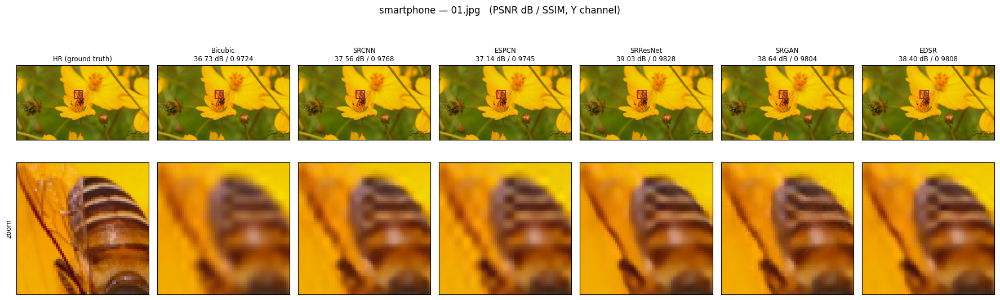

  saved -> sr_outputs\figures\smartphone_02_02.png


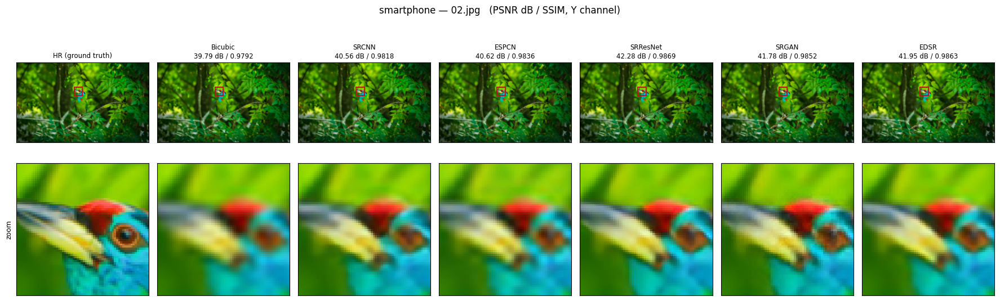

  saved -> sr_outputs\figures\smartphone_03_03.png


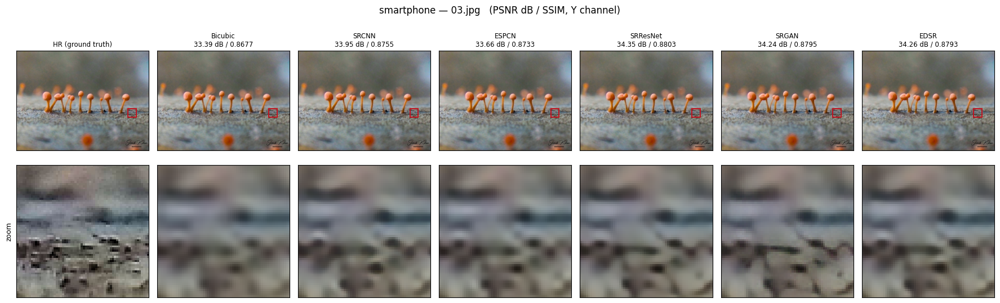

  saved -> sr_outputs\figures\smartphone_04_04.png


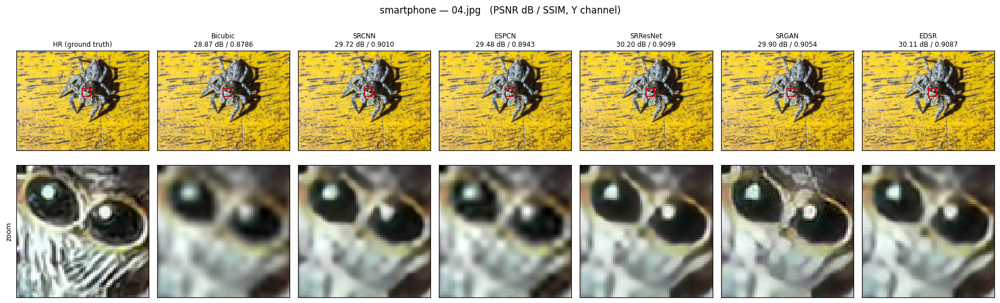

  saved -> sr_outputs\figures\smartphone_05_05.png


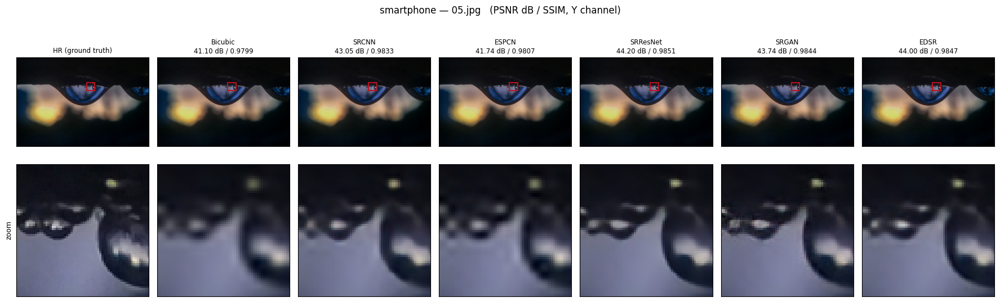

  saved -> sr_outputs\figures\smartphone_06_06.png


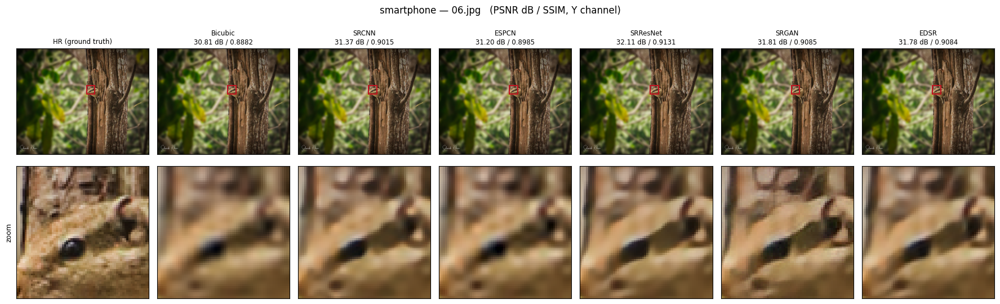

  saved -> sr_outputs\figures\smartphone_07_07.png


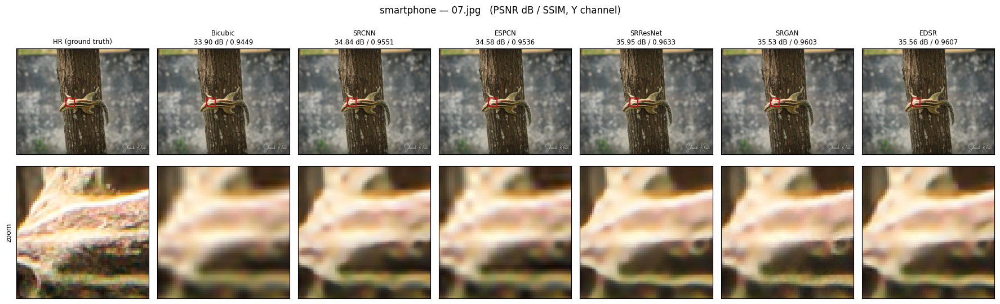

  saved -> sr_outputs\figures\smartphone_08_08.png


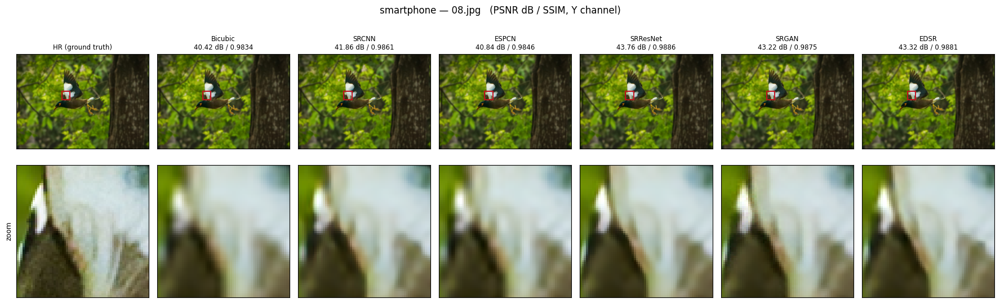

  saved -> sr_outputs\figures\smartphone_09_09.png


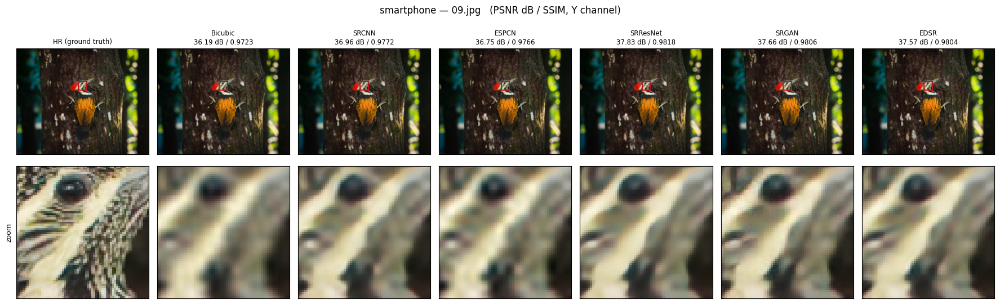

  saved -> sr_outputs\figures\smartphone_10_10.png


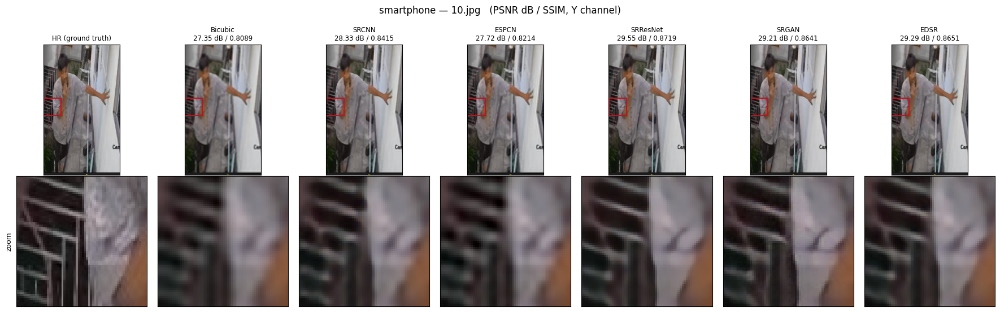


smartphone — mean over 10 images
Method          PSNR-Y    SSIM-Y   PSNR-RGB   Time (ms)      Params
-------------------------------------------------------------------
Bicubic        34.854dB    0.9276    33.307dB           —           —
SRCNN          35.820dB    0.9380    34.188dB        10.4      69,251
ESPCN          35.373dB    0.9341    33.656dB         0.8      37,200
SRResNet       36.927dB    0.9464    35.220dB        30.1   1,548,547
SRGAN          36.572dB    0.9436    34.854dB        29.9   1,548,547
EDSR           36.624dB    0.9442    34.949dB        10.0   1,517,571
saved -> sr_outputs\results\metrics_smartphone.csv


C:\Users\User\AppData\Local\Temp\ipykernel_21288\517445801.py:11: RuntimeWarning: Mean of empty slice
  time_ms=float(np.nanmean([r["time_ms"] for r in rs])),


In [21]:
SMARTPHONE_DIR = Path("smartphone_images")
SMARTPHONE_DIR.mkdir(exist_ok=True)

phone_paths = sorted(p for p in SMARTPHONE_DIR.rglob("*") if p.suffix.lower() in IMG_EXT)

if len(phone_paths) == 0:
    print(f"!! No images in {SMARTPHONE_DIR.resolve()}")
    print("!! Falling back to held-out dataset images so the notebook completes.")
    print("!! Task 6 requires at least 10 of your own photographs — add them and re-run.")
    phone_paths = TEST_IMAGES[:10]
    phone_tag = "smartphone_FALLBACK"
elif len(phone_paths) < 10:
    print(f"!! Only {len(phone_paths)} images found; the task asks for at least 10.")
    phone_tag = "smartphone"
else:
    print(f"Found {len(phone_paths)} smartphone images.")
    phone_tag = "smartphone"

if QUICK_MODE:
    phone_paths = phone_paths[:2]

phone_records = evaluate_image_set(phone_paths, phone_tag)
phone_agg = aggregate(phone_records, phone_tag)

## 15. Quantitative comparison

In [22]:
# --- master table: quality, cost and complexity side by side ---
print(f"{'Method':<12}{'PSNR-Y':>10}{'SSIM-Y':>9}{'Params':>12}{'Size MB':>10}"
      f"{'Infer ms':>10}{'Train s':>10}{'Epochs':>8}")
print("-" * 81)
master_rows = []
for m in METHOD_ORDER:
    a = phone_agg[m]
    if m == "Bicubic":
        row = [m, f"{a['psnr_y']:.3f}", f"{a['ssim_y']:.4f}", "0", "0.00",
               f"{a['time_ms']:.1f}" if not math.isnan(a["time_ms"]) else "—", "0", "0"]
    else:
        s, h = ARCH_STATS[m], HISTORY[m]
        row = [m, f"{a['psnr_y']:.3f}", f"{a['ssim_y']:.4f}", f"{s['params']:,}",
               f"{s['size_mb']:.2f}", f"{a['time_ms']:.1f}",
               f"{h['train_time_s']:.0f}", f"{h['epochs']}"]
    master_rows.append(row)
    print(f"{row[0]:<12}{row[1]:>10}{row[2]:>9}{row[3]:>12}{row[4]:>10}"
          f"{row[5]:>10}{row[6]:>10}{row[7]:>8}")

with open(RESDIR / "comparison_master.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["Method", "PSNR_Y_dB", "SSIM_Y", "Parameters", "Size_MB",
                "Inference_ms", "Train_time_s", "Epochs"])
    w.writerows(master_rows)
print(f"saved -> {RESDIR / 'comparison_master.csv'}")

Method          PSNR-Y   SSIM-Y      Params   Size MB  Infer ms   Train s  Epochs
---------------------------------------------------------------------------------
Bicubic         34.854   0.9276           0      0.00         —         0       0
SRCNN           35.820   0.9380      69,251      0.26      10.4       340      60
ESPCN           35.373   0.9341      37,200      0.14       0.8       173      60
SRResNet        36.927   0.9464   1,548,547      5.92      30.1      1119      60
SRGAN           36.572   0.9436   1,548,547      5.92      29.9       802      25
EDSR            36.624   0.9442   1,517,571      5.79      10.0       390      60
saved -> sr_outputs\results\comparison_master.csv


  saved -> sr_outputs\figures\comparison_metrics.png


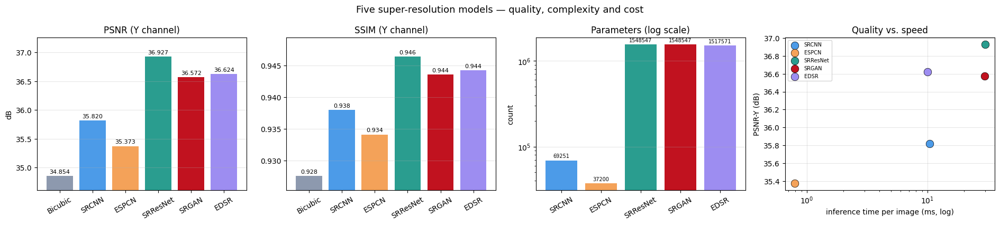

In [23]:
# --- bar charts and the quality/cost trade-off ---
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
methods = METHOD_ORDER
cols = [COLORS[m] for m in methods]

for ax, (vals, title, unit) in zip(axes[:2], [
        ([phone_agg[m]["psnr_y"] for m in methods], "PSNR (Y channel)", "dB"),
        ([phone_agg[m]["ssim_y"] for m in methods], "SSIM (Y channel)", "")]):
    bars = ax.bar(methods, vals, color=cols)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
    ax.set_title(title); ax.set_ylabel(unit); ax.grid(axis="y", alpha=.3)
    ax.tick_params(axis="x", rotation=30)
    lo, hi = min(vals), max(vals)
    ax.set_ylim(lo - 0.12 * (hi - lo + 1e-6), hi + 0.16 * (hi - lo + 1e-6))

ax = axes[2]
bars = ax.bar(MODEL_ORDER, [ARCH_STATS[m]["params"] for m in MODEL_ORDER],
              color=[COLORS[m] for m in MODEL_ORDER])
ax.bar_label(bars, fmt="%.0f", fontsize=7, padding=2)
ax.set_yscale("log"); ax.set_title("Parameters (log scale)"); ax.set_ylabel("count")
ax.tick_params(axis="x", rotation=30); ax.grid(axis="y", alpha=.3)

ax = axes[3]
for m in methods:
    t = phone_agg[m]["time_ms"]
    if not math.isnan(t):
        ax.scatter(t, phone_agg[m]["psnr_y"], s=110, color=COLORS[m],
                   edgecolor="black", linewidth=.5, label=m, zorder=3)
ax.set_xscale("log")
ax.set_xlabel("inference time per image (ms, log)"); ax.set_ylabel("PSNR-Y (dB)")
ax.set_title("Quality vs. speed"); ax.grid(alpha=.3); ax.legend(fontsize=7)

fig.suptitle("Five super-resolution models — quality, complexity and cost", fontsize=13)
plt.tight_layout()
savefig(fig, "comparison_metrics")
plt.show()

  saved -> sr_outputs\figures\comparison_per_image.png


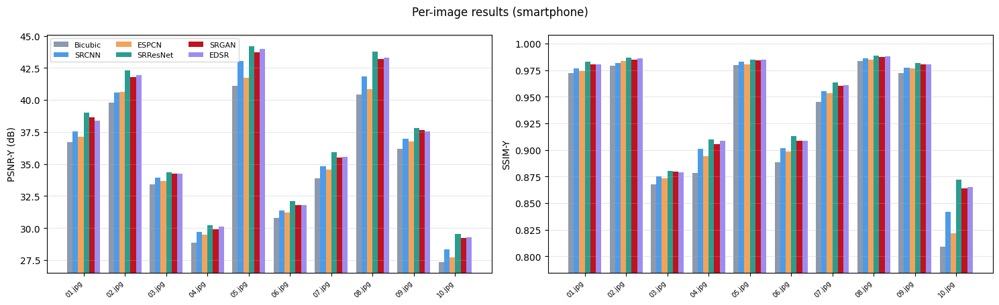

In [24]:
# --- per-image spread: averages hide which images are hard ---
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
names = sorted({r["image"] for r in phone_records})
x = np.arange(len(names)); width = 0.8 / len(METHOD_ORDER)

for ax, key, label in zip(axes, ["psnr_y", "ssim_y"], ["PSNR-Y (dB)", "SSIM-Y"]):
    for i, m in enumerate(METHOD_ORDER):
        vals = [next(r[key] for r in phone_records if r["image"] == nm and r["method"] == m)
                for nm in names]
        ax.bar(x + (i - len(METHOD_ORDER) / 2 + .5) * width, vals, width,
               label=m, color=COLORS[m])
    ax.set_xticks(x)
    ax.set_xticklabels([n[:14] for n in names], rotation=45, ha="right", fontsize=7)
    ax.set_ylabel(label); ax.grid(axis="y", alpha=.3)
    lo = min(r[key] for r in phone_records)
    ax.set_ylim(lo * 0.97, max(r[key] for r in phone_records) * 1.02)
axes[0].legend(fontsize=8, ncol=3)
fig.suptitle(f"Per-image results ({phone_tag})", fontsize=12)
plt.tight_layout()
savefig(fig, "comparison_per_image")
plt.show()

In [25]:
# --- efficiency: quality gained over the bicubic baseline, per unit of cost ---
base = phone_agg["Bicubic"]["psnr_y"]
print(f"Bicubic baseline: {base:.3f} dB — everything below is the gain over it\n")
print(f"{'Model':<12}{'ΔPSNR':>9}{'ΔPSNR / M param':>18}{'ΔPSNR / ms':>13}"
      f"{'ΔPSNR / train-min':>20}")
print("-" * 72)
for m in MODEL_ORDER:
    d = phone_agg[m]["psnr_y"] - base
    s, h = ARCH_STATS[m], HISTORY[m]
    print(f"{m:<12}{d:+8.3f}dB{d/(s['params']/1e6):18.2f}"
          f"{d/max(phone_agg[m]['time_ms'],1e-9):13.4f}"
          f"{d/max(h['train_time_s']/60,1e-9):20.4f}")

Bicubic baseline: 34.854 dB — everything below is the gain over it

Model           ΔPSNR   ΔPSNR / M param   ΔPSNR / ms   ΔPSNR / train-min
------------------------------------------------------------------------
SRCNN         +0.966dB             13.95       0.0930              0.1703
ESPCN         +0.519dB             13.95       0.6561              0.1795
SRResNet      +2.072dB              1.34       0.0688              0.1111
SRGAN         +1.718dB              1.11       0.0574              0.1285
EDSR          +1.770dB              1.17       0.1768              0.2720
